![AudioMetrics - Juan David Cabrera](https://raw.githubusercontent.com/juandaCbr/AudioMetrics/main/assets/banner.png)

## 1. Carga del dataset

Fuente: Spotify Tracks Dataset (114,000 canciones, 20 columnas originales, 114 generos musicales).

Si estas corriendo esto en Google Colab, sube `dataset.csv` a la sesion (icono de carpeta en el panel izquierdo) antes de ejecutar la siguiente celda.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('dataset.csv')
print("Shape original:", df.shape)
df.head()

Shape original: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 2. Limpieza: columna de indice residual

El CSV original trae una columna `Unnamed: 0` que es solo el indice de fila — no aporta informacion al modelo.

In [2]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Shape tras eliminar Unnamed: 0:", df.shape)

Shape tras eliminar Unnamed: 0: (114000, 20)


## 3. Eliminacion de outliers (metodo IQR)

Se aplica el metodo estadistico de cuartiles sobre las tres variables numericas mas sensibles a valores extremos: `duration_ms`, `loudness` y `tempo`.

In [3]:
def limpiar_outliers_iqr(dataframe, columna):
    Q1 = dataframe[columna].quantile(0.25)
    Q3 = dataframe[columna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    return dataframe[(dataframe[columna] >= limite_inferior) & (dataframe[columna] <= limite_superior)]

shape_antes = df.shape
df = limpiar_outliers_iqr(df, 'duration_ms')
df = limpiar_outliers_iqr(df, 'loudness')
df = limpiar_outliers_iqr(df, 'tempo')

print("Shape antes de quitar outliers:", shape_antes)
print("Shape despues de quitar outliers:", df.shape)

Shape antes de quitar outliers: (114000, 20)
Shape despues de quitar outliers: (102309, 20)


## 4. Duplicados y valores nulos

Se eliminan canciones duplicadas (mismo `track_id`) y filas con valores nulos.

In [4]:
shape_antes = df.shape
df = df.drop_duplicates(subset=['track_id'], keep='first')
df = df.dropna()

print("Shape antes:", shape_antes)
print("Shape despues de duplicados/nulos:", df.shape)

Shape antes: (102309, 20)
Shape despues de duplicados/nulos: (79600, 20)


## 5. Columnas de texto y variables booleanas

`track_id` y `album_name` se eliminan porque no aportan al modelo matematico.
`artists` y `track_name` **se conservan** — son necesarios para el modo "Cancion Existente" del producto final (buscar canciones reales y calcular metricas por artista).
`explicit` (booleana) se convierte a 0/1.

In [5]:
columnas_texto = ['track_id', 'album_name']
df = df.drop(columns=[col for col in columnas_texto if col in df.columns])

if 'explicit' in df.columns:
    df['explicit'] = df['explicit'].astype(int)

print("Columnas actuales:", list(df.columns[:12]), "...")

Columnas actuales: ['artists', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness'] ...


## 6. One-Hot Encoding de `track_genre`

Se transforma la columna categorica de genero en variables binarias. `drop_first=True` evita multicolinealidad perfecta.

In [6]:
if 'track_genre' in df.columns:
    df = pd.get_dummies(df, columns=['track_genre'], drop_first=True)

print("Shape final del dataset limpio y codificado:", df.shape)

Shape final del dataset limpio y codificado: (79600, 129)


## 7. Vista previa del dataset limpio

Se transpone la tabla (cada cancion como columna) para que se lea de forma ordenada, dado que el dataset ya tiene más de 100 columnas por el one-hot encoding de genero.

In [7]:
pd.set_option('display.max_rows', None)

cols_no_genero = [c for c in df.columns if not c.startswith('track_genre_')]
df[cols_no_genero].head(15).T

,0,1,2,4,5,6,7,8,9,10,11,12,13,14,15
artists,Gen Hoshino,Ben Woodward,Ingrid Michaelson;ZAYN,Chord Overstreet,Tyrone Wells,A Great Big World;Christina Aguilera,Jason Mraz,Jason Mraz;Colbie Caillat,Ross Copperman,Zack Tabudlo,Jason Mraz,Dan Berk,Anna Hamilton,Chord Overstreet;Deepend,Landon Pigg
track_name,Comedy,Ghost - Acoustic,To Begin Again,Hold On,Days I Will Remember,Say Something,I'm Yours,Lucky,Hunger,Give Me Your Forever,I Won't Give Up,Solo,Bad Liar,Hold On - Remix,Falling in Love at a Coffee Shop
popularity,73,55,57,82,58,74,80,74,56,74,69,52,62,56,58
duration_ms,230666,149610,210826,198853,214240,229400,242946,189613,205594,244800,240165,198712,248448,188133,244986
explicit,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
danceability,0.676,0.42,0.438,0.618,0.688,0.407,0.703,0.625,0.442,0.627,0.483,0.489,0.691,0.755,0.489
energy,0.461,0.166,0.359,0.443,0.481,0.147,0.444,0.414,0.632,0.363,0.303,0.314,0.234,0.78,0.561
key,1,1,0,2,6,2,11,0,1,8,4,7,3,2,4
loudness,-6.746,-17.235,-9.734,-9.681,-8.807,-8.822,-9.331,-8.7,-6.77,-8.127,-10.058,-9.245,-6.441,-6.084,-7.933
mode,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1


In [8]:
df.to_csv('dataset_limpio.csv', index=False)
print("Archivo guardado como dataset_limpio.csv")

Archivo guardado como dataset_limpio.csv


## 8. Analisis exploratorio: ¿que variables acusticas se correlacionan con `popularity`?

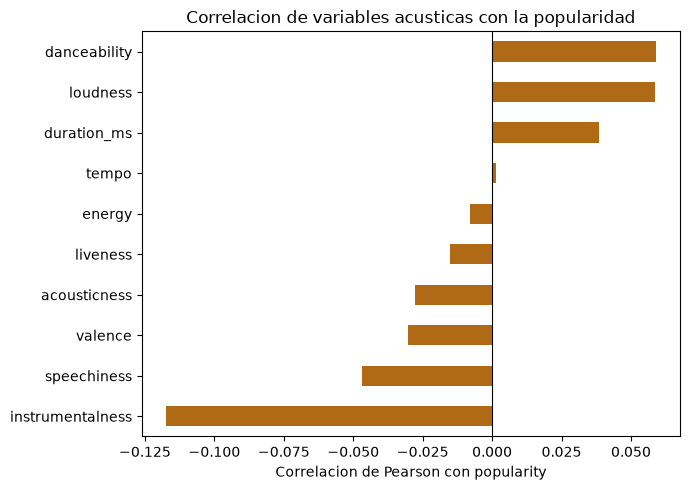

instrumentalness   -0.117338
speechiness        -0.046857
valence            -0.030399
acousticness       -0.027675
liveness           -0.015107
energy             -0.007973
tempo               0.001577
duration_ms         0.038630
loudness            0.058508
danceability        0.058839
dtype: float64

In [9]:
variables_acusticas = ['danceability', 'energy', 'loudness', 'speechiness',
                       'acousticness', 'instrumentalness', 'liveness', 'valence',
                       'tempo', 'duration_ms']

correlaciones = df[variables_acusticas].corrwith(df['popularity']).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
correlaciones.plot(kind='barh', ax=ax, color='#B06A16')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlacion de Pearson con popularity')
ax.set_title('Correlacion de variables acusticas con la popularidad')
plt.tight_layout()
plt.show()

correlaciones

## 9. El hallazgo: variables derivadas de columnas de texto

Ninguna variable acustica por si sola tiene una correlacion fuerte con `popularity`. Se exploro si se podia derivar una senal mas fuerte a partir de `artists` (una columna de texto que en apariencia "no servia para el modelo matematico").

Se calculo `artist_avg_popularity` con estrategia **leave-one-out**: el promedio de popularidad de las **demas** canciones del mismo artista, excluyendo la propia cancion (para evitar fuga de datos / data leakage) durante esta exploracion.

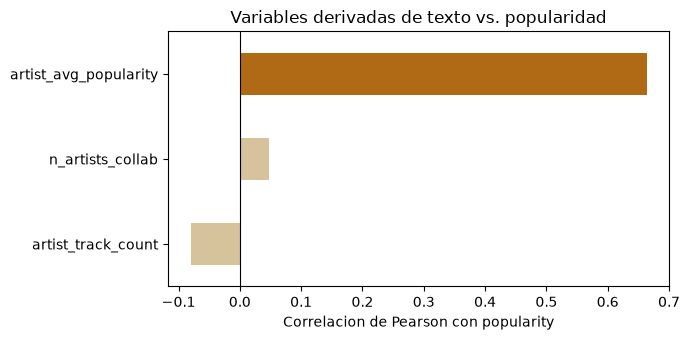

artist_track_count      -0.080391
n_artists_collab         0.047854
artist_avg_popularity    0.663367
dtype: float64

In [10]:
suma_por_artista = df.groupby('artists')['popularity'].transform('sum')
conteo_por_artista = df.groupby('artists')['popularity'].transform('count')

df['artist_avg_popularity'] = (suma_por_artista - df['popularity']) / (conteo_por_artista - 1)
df['artist_avg_popularity'] = df['artist_avg_popularity'].fillna(df['popularity'].mean())

df['artist_track_count'] = conteo_por_artista
df['n_artists_collab'] = df['artists'].apply(lambda x: len(str(x).split(';')))

features_derivadas = ['artist_avg_popularity', 'artist_track_count', 'n_artists_collab']
correlaciones_derivadas = df[features_derivadas].corrwith(df['popularity']).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
colores = ['#B06A16' if abs(v) > 0.3 else '#D6C29B' for v in correlaciones_derivadas]
correlaciones_derivadas.plot(kind='barh', ax=ax, color=colores)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlacion de Pearson con popularity')
ax.set_title('Variables derivadas de texto vs. popularidad')
plt.tight_layout()
plt.show()

correlaciones_derivadas

**Conclusion del hallazgo:** `artist_avg_popularity` obtiene una correlacion de **0.66**, muy por encima de cualquier variable acustica original (todas por debajo de 0.1-0.2). `artist_track_count` y `n_artists_collab` no aportan senal util y se descartan.

Esto confirma algo esperado en la literatura de *Music Information Retrieval*: la popularidad depende mas de **quien** canta que de **como suena** la cancion.

## 10. Definicion del umbral Hit / Nicho

La propuesta original del proyecto usaba un umbral fijo: `popularity > 75` = Hit. Antes de programar el Random Forest en la Entrega 2, se valida si ese umbral es viable revisando la distribucion real de `popularity`.

In [11]:
print(df['popularity'].describe())

count    79600.000000
mean        33.831947
std         20.664872
min          0.000000
25%         20.000000
50%         34.000000
75%         49.000000
max        100.000000
Name: popularity, dtype: float64


In [12]:
for umbral in [50, 60, 70, 75, 80]:
    pct = (df['popularity'] > umbral).mean() * 100
    print(f"Canciones con popularity > {umbral}: {pct:.2f}%")

Canciones con popularity > 50: 23.05%
Canciones con popularity > 60: 10.51%
Canciones con popularity > 70: 3.37%
Canciones con popularity > 75: 1.59%
Canciones con popularity > 80: 0.62%


Con el umbral fijo de 75, solo el **1.59%** de las canciones califican como "Hit" — un desbalance de clases severo, insuficiente para que un Random Forest aprenda patrones reales (un modelo que siempre prediga "Nicho" ya acertaria ~98% sin haber aprendido nada).

**Decision tomada:** definir el umbral por **percentil** en vez de un valor fijo. `HIT_PERCENTIL = 0.85` -> Hit = estar en el top 15% de popularidad del dataset.

In [13]:
HIT_PERCENTIL = 0.85

for p in [0.80, 0.85, 0.90]:
    corte = df['popularity'].quantile(p)
    pct_arriba = (df['popularity'] > corte).mean() * 100
    print(f"Percentil {int(p*100)} -> popularity > {corte:.1f} -> {pct_arriba:.2f}% de la clase Hit")

corte_final = df['popularity'].quantile(HIT_PERCENTIL)
df['es_hit'] = (df['popularity'] > corte_final).astype(int)

print()
print(f"Corte final (percentil {int(HIT_PERCENTIL*100)}): popularity > {corte_final:.1f}")
print(df['es_hit'].value_counts(normalize=True) * 100)

Percentil 80 -> popularity > 53.0 -> 19.16% de la clase Hit
Percentil 85 -> popularity > 57.0 -> 13.92% de la clase Hit
Percentil 90 -> popularity > 61.0 -> 9.60% de la clase Hit

Corte final (percentil 85): popularity > 57.0
es_hit
0    86.081658
1    13.918342
Name: proportion, dtype: float64


Se eligio el **percentil 85** como punto intermedio entre tener suficientes ejemplos positivos para entrenar y que "Hit" siga significando algo real (top 15%, no la mitad de arriba). El corte numerico (`popularity > ~57`) no se debe hardcodear en el pipeline final: se recalcula con `.quantile(0.85)` sobre el conjunto de **entrenamiento** en la Entrega 2, para mantener la logica consistente si el dataset de entrada cambia. Junto con esta definicion, la Entrega 2 debe usar `train_test_split(..., stratify=y)` y `class_weight='balanced'` en el Random Forest, evaluando con precision/recall/F1 en lugar de accuracy.

## 11. Decisiones de arquitectura y limitaciones confirmadas

**Arquitectura de dos modos en el producto final:**

- **Modo "Cancion nueva":** el usuario ajusta libremente variables acusticas sin identidad de artista. El modelo de produccion para este modo se entrena **solo** con variables acusticas + genero — sin `artist_avg_popularity` — porque una cancion/artista nuevo no tiene historial (problema de *cold-start*).
- **Modo "Cancion existente":** el usuario indica un artista real. Aqui si se usa `artist_avg_popularity`, calculada correctamente **solo sobre el conjunto de entrenamiento** (no sobre todo el dataset) para evitar fuga de datos hacia el conjunto de prueba.

**Limitaciones confirmadas del dataset:**

- No existe columna de fecha de lanzamiento (`release_date`) en el CSV original.
- Es una foto fija (snapshot, ~2022): un unico valor de popularidad por cancion, sin serie temporal. No se puede predecir la evolucion de la popularidad en el tiempo con estos datos.
- Faltan variables de marketing, playlists y promocion — por lo tanto se espera un techo de R² moderado en la regresion de popularidad, y no es una falla del pipeline sino una limitacion conocida del problema.

---
# ENTREGA 2 — Modelos supervisados de clasificacion

## 12. Planteamiento del problema supervisado

**Tarea:** clasificacion binaria. Dada una cancion, predecir si es **Hit** (top 15% de popularidad, `es_hit = 1`) o **Nicho** (`es_hit = 0`).

**Variables de entrada (modo "Cancion nueva"):** solo variables acusticas (`danceability`, `energy`, `tempo`, etc.), variables musicales (`key`, `mode`, `time_signature`, `explicit`, `duration_ms`) y el genero codificado con One-Hot. Se excluyen `artists`, `track_name` y todas las variables derivadas del artista (`artist_avg_popularity`, etc.), porque una cancion nueva no tiene historial (cold-start, ver seccion 11). Tambien se excluye `popularity`, que es de donde sale la etiqueta.

**Metrica principal: F1 de la clase Hit.** Como la clase Hit es solo ~15% de los datos, la *accuracy* es enganosa: un modelo que siempre responda "Nicho" tendria ~85% de accuracy sin aprender nada. El F1 combina precision y recall de la clase minoritaria, que es la que interesa detectar. Todos los modelos usan `class_weight='balanced'` para compensar el desbalance.

**Mapa de los requisitos de la Entrega 2 en este notebook:**

| Requisito | Seccion |
|---|---|
| 1. Limpieza del dataset, datos nulos | 13 |
| 2. Particionado 80/20 | 14 |
| 3. DecisionTree (curva para `max_depth`) | 15 |
| 3. RandomForest (curva para `n_estimators`) | 16 |
| 3. SVM (curva para `kernel` linear, poly, rbf) | 17 |
| 4. CrossValidation (curva para elegir el numero de iteraciones) | 18 |
| 5. Deep Learning: MLP de 3, 6 y 10 capas ocultas | 19 |
| 6. Epochs: experimento con 5, 10, 50 y 100 | 19 |
| Barplot final DT, RF, SVM, DL | 20 |

In [14]:
import time
import numpy as np

from sklearn.model_selection import (train_test_split, StratifiedKFold, validation_curve,
                                     cross_val_score, learning_curve)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, classification_report, ConfusionMatrixDisplay)

# Semilla global para que todos los resultados sean reproducibles
SEMILLA = 42
np.random.seed(SEMILLA)

# Paleta de colores consistente con las graficas de la Entrega 1
COLOR_TRAIN = '#D6C29B'
COLOR_VAL = '#B06A16'

## 13. Limpieza y verificacion del dataset para modelado

El dataset ya fue limpiado en la Entrega 1 (outliers por IQR, duplicados por `track_id`, nulos, One-Hot de genero). Antes de entrenar se verifica de nuevo y se prepara la matriz de modelado:

1. Se quitan las columnas de texto y las variables derivadas del artista (no aplican al modo "Cancion nueva").
2. Se convierten las columnas booleanas del One-Hot (`True/False`) a enteros `0/1`.
3. Se verifica que no queden valores nulos.
4. Se eliminan filas **exactamente duplicadas** en todas sus variables: el mismo audio publicado con distinto `track_id` (por ejemplo, la misma cancion en un single y en un album). Si se dejaran, una copia podria caer en train y otra en test, inflando artificialmente el desempeno.

In [15]:
# Columnas que no se usan en el modo 'Cancion nueva'
columnas_excluidas = ['artists', 'track_name', 'artist_avg_popularity',
                      'artist_track_count', 'n_artists_collab', 'es_hit']
df_ml = df.drop(columns=[c for c in columnas_excluidas if c in df.columns]).copy()

# Conversion de columnas booleanas (One-Hot) a enteros 0/1
columnas_bool = df_ml.select_dtypes(include='bool').columns
df_ml[columnas_bool] = df_ml[columnas_bool].astype(int)

# Verificacion de nulos
print("Valores nulos totales:", df_ml.isna().sum().sum())

# Eliminacion de filas exactamente duplicadas
duplicados = df_ml.duplicated().sum()
df_ml = df_ml.drop_duplicates().reset_index(drop=True)
print("Filas duplicadas eliminadas:", duplicados)

# Verificacion de que todas las columnas son numericas
columnas_no_numericas = df_ml.select_dtypes(exclude='number').columns.tolist()
print("Columnas no numericas:", columnas_no_numericas)

print("Shape de la matriz de modelado:", df_ml.shape)

Valores nulos totales: 0


Filas duplicadas eliminadas: 3483
Columnas no numericas: []
Shape de la matriz de modelado: (76117, 127)


## 14. Particionado 80/20

- **80% entrenamiento / 20% prueba**, con `random_state` fijo.
- La particion se **estratifica por deciles de `popularity`**, de modo que train y test tengan la misma distribucion de popularidad (y por lo tanto la misma proporcion de Hits).
- Tal como se decidio en la Entrega 1, el corte de Hit se calcula con `quantile(0.85)` **solo sobre el conjunto de entrenamiento** y luego se aplica a ambos conjuntos. Asi el conjunto de prueba no influye en ninguna decision del modelo.
- El conjunto de prueba **no se usa** para elegir hiperparametros: todas las curvas de las secciones 15 a 19 se calculan con validacion cruzada o con una particion de validacion sacada del train. El test solo se usa una vez, en la comparacion final (seccion 20).

In [16]:
X = df_ml.drop(columns=['popularity'])
popularidad = df_ml['popularity']

# Estratificacion por deciles de popularidad
deciles = pd.qcut(popularidad, q=10, labels=False, duplicates='drop')

X_train, X_test, pop_train, pop_test = train_test_split(
    X, popularidad, test_size=0.20, random_state=SEMILLA, stratify=deciles)

# Corte de Hit calculado unicamente con el conjunto de entrenamiento
corte_hit = pop_train.quantile(HIT_PERCENTIL)
y_train = (pop_train > corte_hit).astype(int)
y_test = (pop_test > corte_hit).astype(int)

print(f"Corte Hit (percentil {int(HIT_PERCENTIL*100)} del train): popularity > {corte_hit:.1f}")
print(f"Train: {X_train.shape[0]:,} filas | Test: {X_test.shape[0]:,} filas | Variables: {X_train.shape[1]}")
print(f"Proporcion de Hits en train: {y_train.mean()*100:.2f}%")
print(f"Proporcion de Hits en test:  {y_test.mean()*100:.2f}%")

Corte Hit (percentil 85 del train): popularity > 57.0
Train: 60,893 filas | Test: 15,224 filas | Variables: 126
Proporcion de Hits en train: 14.53%
Proporcion de Hits en test:  14.60%


In [17]:
# Escalado estandar (media 0, desviacion 1) ajustado solo con train.
# Lo necesitan SVM y la red neuronal; los arboles no son sensibles a la escala.
scaler = StandardScaler().fit(X_train)
X_train_esc = scaler.transform(X_train)
X_test_esc = scaler.transform(X_test)

# Validacion cruzada estratificada de 5 particiones para las curvas de hiperparametros
# (la eleccion del numero de particiones se justifica en la seccion 18)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)


def graficar_curva_validacion(valores, scores_train, scores_val, titulo, etiqueta_x, etiquetas=None):
    # Grafica la media y desviacion del F1 en train y validacion para cada valor del hiperparametro
    media_tr, std_tr = scores_train.mean(axis=1), scores_train.std(axis=1)
    media_va, std_va = scores_val.mean(axis=1), scores_val.std(axis=1)
    x = np.arange(len(valores)) if etiquetas is not None else np.array(valores)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(x, media_tr, 'o-', color=COLOR_TRAIN, label='Entrenamiento')
    ax.fill_between(x, media_tr - std_tr, media_tr + std_tr, color=COLOR_TRAIN, alpha=0.25)
    ax.plot(x, media_va, 'o-', color=COLOR_VAL, label='Validacion (CV)')
    ax.fill_between(x, media_va - std_va, media_va + std_va, color=COLOR_VAL, alpha=0.25)

    mejor = int(np.argmax(media_va))
    ax.axvline(x[mejor], color='black', linestyle='--', linewidth=0.8)
    ax.annotate(f'mejor validacion = {media_va[mejor]:.3f}', xy=(x[mejor], media_va[mejor]),
                xytext=(10, -25), textcoords='offset points', fontsize=9)

    if etiquetas is not None:
        ax.set_xticks(x)
        ax.set_xticklabels(etiquetas)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel('F1 clase Hit')
    ax.set_title(titulo)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame({etiqueta_x: valores if etiquetas is None else etiquetas,
                         'F1 train': media_tr.round(4), 'F1 validacion': media_va.round(4),
                         'Desv. validacion': std_va.round(4)})

## 15. Decision Tree — curva para `max_depth`

`max_depth` controla cuantas preguntas consecutivas puede hacer el arbol. Con poca profundidad el modelo es demasiado simple (*underfitting*: F1 bajo en train y en validacion). Con mucha profundidad el arbol memoriza el entrenamiento (*overfitting*: F1 de train cercano a 1 pero la validacion cae). Se busca el punto donde la curva de validacion es maxima.

Tiempo: 26.9 s


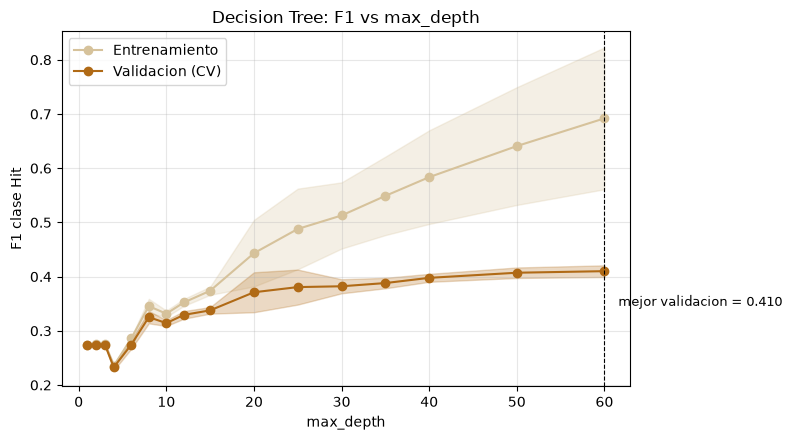

Mejor max_depth: 60


,max_depth,F1 train,F1 validacion,Desv. validacion
0,1,0.2744,0.2735,0.0018
1,2,0.2754,0.2745,0.0014
2,3,0.2755,0.2743,0.0015
3,4,0.2355,0.2327,0.0057
4,6,0.2860,0.2745,0.0076
5,8,0.3455,0.3252,0.0114
6,10,0.3315,0.3142,0.0054
7,12,0.3523,0.3294,0.0071
8,15,0.3739,0.3377,0.0061
9,20,0.4432,0.3711,0.0369


In [18]:
profundidades = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, 25, 30, 35, 40, 50, 60]

inicio = time.time()
scores_tr_dt, scores_va_dt = validation_curve(
    DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA),
    X_train, y_train, param_name='max_depth', param_range=profundidades,
    cv=cv5, scoring='f1', n_jobs=-1)
print(f"Tiempo: {time.time() - inicio:.1f} s")

tabla_dt = graficar_curva_validacion(profundidades, scores_tr_dt, scores_va_dt,
                                     'Decision Tree: F1 vs max_depth', 'max_depth')
mejor_max_depth = profundidades[int(np.argmax(scores_va_dt.mean(axis=1)))]
print("Mejor max_depth:", mejor_max_depth)
tabla_dt

**Analisis de la curva (Decision Tree):**
- Con profundidades bajas (1 a 6) el arbol tiene *underfitting*: el F1 de validacion se queda en ~0.27, practicamente igual al de train. Con tan pocas preguntas el arbol solo alcanza a separar unos pocos generos.
- A partir de `max_depth = 8` ambos F1 suben. El de validacion sigue creciendo hasta **0.410 con `max_depth = 60`**, pero cada vez mas lento (de 50 a 60 solo gana 0.003): la curva ya esta en su meseta.
- La brecha entre train (0.69) y validacion (0.41) crece con la profundidad: el arbol empieza a memorizar el entrenamiento (*overfitting*). Aun asi, la validacion no cae, porque la popularidad depende de combinaciones muy especificas de genero y variables acusticas, y para capturarlas el arbol necesita muchas divisiones.
- **Valor elegido: `max_depth = 60`** (el maximo F1 de validacion). Incluso en su mejor configuracion, el Decision Tree es el modelo mas debil: un solo arbol tiene alta varianza. Esa es justamente la motivacion del Random Forest.

## 16. Random Forest — curva para `n_estimators`

`n_estimators` es el numero de arboles del bosque. Cada arbol se entrena con una muestra bootstrap distinta y un subconjunto aleatorio de variables; la prediccion final es la votacion de todos. Mas arboles reducen la varianza, pero a partir de cierto punto la mejora es marginal y solo aumenta el costo computacional.

Para que `class_weight='balanced'` tenga efecto real se usa `min_samples_leaf=5`: con hojas de una sola muestra (valor por defecto) cada hoja es pura y el peso de clase no cambia la prediccion.

Tiempo: 106.3 s


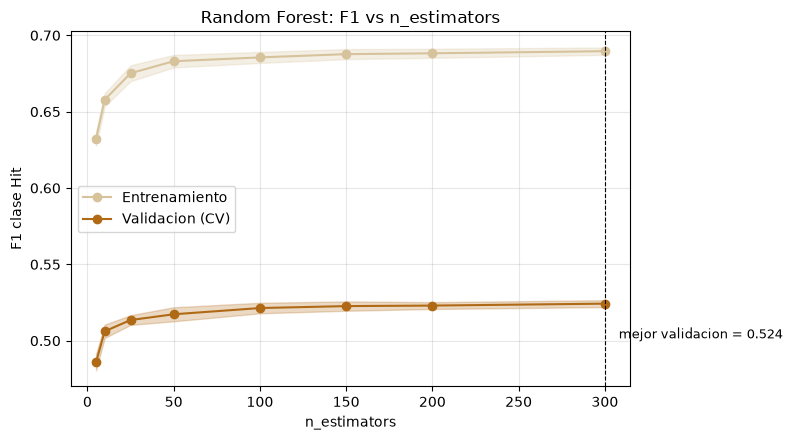

n_estimators elegido: 100


,n_estimators,F1 train,F1 validacion,Desv. validacion
0,5,0.6322,0.4859,0.0054
1,10,0.6578,0.5062,0.0044
2,25,0.6752,0.5135,0.0032
3,50,0.6830,0.5173,0.0046
4,100,0.6855,0.5214,0.0034
5,150,0.6877,0.5227,0.0031
6,200,0.6882,0.5230,0.0022
7,300,0.6896,0.5243,0.0023


In [19]:
n_arboles = [5, 10, 25, 50, 100, 150, 200, 300]

inicio = time.time()
scores_tr_rf, scores_va_rf = validation_curve(
    RandomForestClassifier(class_weight='balanced', min_samples_leaf=5,
                           random_state=SEMILLA, n_jobs=-1),
    X_train, y_train, param_name='n_estimators', param_range=n_arboles,
    cv=cv5, scoring='f1', n_jobs=1)
print(f"Tiempo: {time.time() - inicio:.1f} s")

tabla_rf = graficar_curva_validacion(n_arboles, scores_tr_rf, scores_va_rf,
                                     'Random Forest: F1 vs n_estimators', 'n_estimators')

# Criterio: el menor numero de arboles cuyo F1 de validacion este a menos de 0.005 del maximo.
# Asi se evita pagar el costo de cientos de arboles por una mejora despreciable.
media_va_rf = scores_va_rf.mean(axis=1)
mejor_n_estimators = n_arboles[int(np.argmax(media_va_rf >= media_va_rf.max() - 0.005))]
print("n_estimators elegido:", mejor_n_estimators)
tabla_rf

**Analisis de la curva (Random Forest):**
- El F1 de validacion sube rapido entre 5 y 25 arboles (0.486 -> 0.514) y luego se estabiliza: 100 arboles = 0.521, 300 arboles = 0.524. Triplicar el costo solo mejora 0.003.
- La desviacion entre particiones baja al aumentar los arboles (0.005 -> 0.002): promediar mas arboles reduce la varianza del modelo.
- La brecha train-validacion (~0.69 vs ~0.52) es mucho menor que la del arbol individual con profundidad similar. El *bagging* y la seleccion aleatoria de variables controlan el sobreajuste.
- **Valor elegido: `n_estimators = 100`.** Es el menor numero de arboles cuyo F1 esta a menos de 0.005 del maximo, asi que da el mismo desempeno a un tercio del costo de 300 arboles (importante para la aplicacion web, que debe responder en tiempo real).

## 17. SVM — curva para `kernel` (linear, poly, rbf)

El kernel define la forma de la frontera de decision:
- **linear:** un hiperplano; supone que las clases se separan linealmente.
- **poly:** frontera polinomica (grado 3 por defecto).
- **rbf:** funcion de base radial; puede crear fronteras muy flexibles y locales.

**Consideracion de costo computacional:** el entrenamiento de un SVM con kernel crece aproximadamente con el cuadrado (o mas) del numero de muestras, por lo que entrenarlo con las ~60 mil canciones del train es impracticable en un equipo personal o en Colab. Se usa una **submuestra estratificada de 10,000 canciones del train** para la curva del kernel. Las variables se escalan **dentro** de cada particion de la validacion cruzada (`make_pipeline`) para no filtrar informacion entre particiones.

Submuestra SVM: 10,000 filas, 14.53% Hits


Tiempo: 34.9 s


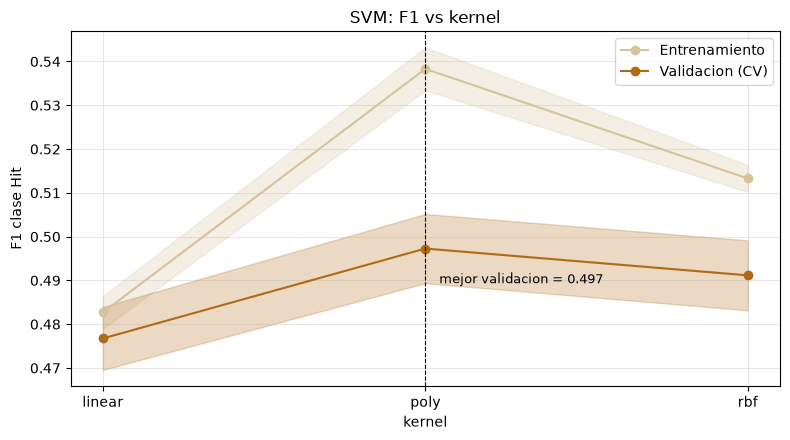

Mejor kernel: poly


,kernel,F1 train,F1 validacion,Desv. validacion
0,linear,0.4827,0.4768,0.0072
1,poly,0.5383,0.4973,0.0079
2,rbf,0.5133,0.4912,0.0080


In [20]:
TAMANO_SUBMUESTRA_SVM = 10000

X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train, y_train, train_size=TAMANO_SUBMUESTRA_SVM, stratify=y_train, random_state=SEMILLA)
print(f"Submuestra SVM: {len(y_train_svm):,} filas, {y_train_svm.mean()*100:.2f}% Hits")

kernels = ['linear', 'poly', 'rbf']

inicio = time.time()
scores_tr_svm, scores_va_svm = validation_curve(
    make_pipeline(StandardScaler(), SVC(class_weight='balanced', cache_size=1000)),
    X_train_svm, y_train_svm, param_name='svc__kernel', param_range=kernels,
    cv=cv5, scoring='f1', n_jobs=-1)
print(f"Tiempo: {time.time() - inicio:.1f} s")

tabla_svm = graficar_curva_validacion(kernels, scores_tr_svm, scores_va_svm,
                                      'SVM: F1 vs kernel', 'kernel', etiquetas=kernels)
mejor_kernel = kernels[int(np.argmax(scores_va_svm.mean(axis=1)))]
print("Mejor kernel:", mejor_kernel)
tabla_svm

**Analisis de la curva (SVM):**
- El kernel **linear** es el peor (F1 validacion 0.477): una frontera lineal no alcanza para separar Hits de Nichos con estas variables.
- Los kernels no lineales mejoran: **poly = 0.497** y **rbf = 0.491**. La diferencia entre ellos (0.006) es menor que la desviacion entre particiones (~0.008), asi que en la practica estan empatados.
- El kernel poly muestra la mayor brecha train-validacion (0.538 vs 0.497), es decir, un poco mas de sobreajuste por ser la frontera mas flexible.
- **Kernel elegido: `poly`** (maximo F1 de validacion). La conclusion de fondo es que la relacion entre las variables y la clase Hit es **no lineal**.

## 18. Validacion cruzada — eleccion del numero de iteraciones (k)

En validacion cruzada *k-fold*, el train se divide en *k* partes y el modelo se entrena *k* veces (*k* iteraciones), cada vez validando con una parte distinta. El numero de iteraciones es un compromiso:

- **k pequeno** (2-3): cada modelo entrena con poca informacion (50-67% del train), la estimacion es pesimista y mas variable.
- **k grande** (10): estimacion mas estable, pero el costo crece linealmente con *k*.

Se evalua el F1 de los tres modelos ya ajustados (DT, RF y SVM con sus mejores hiperparametros) para k = 2, 3, 4, 5, 7 y 10, observando la media y la desviacion del F1 y el tiempo total.

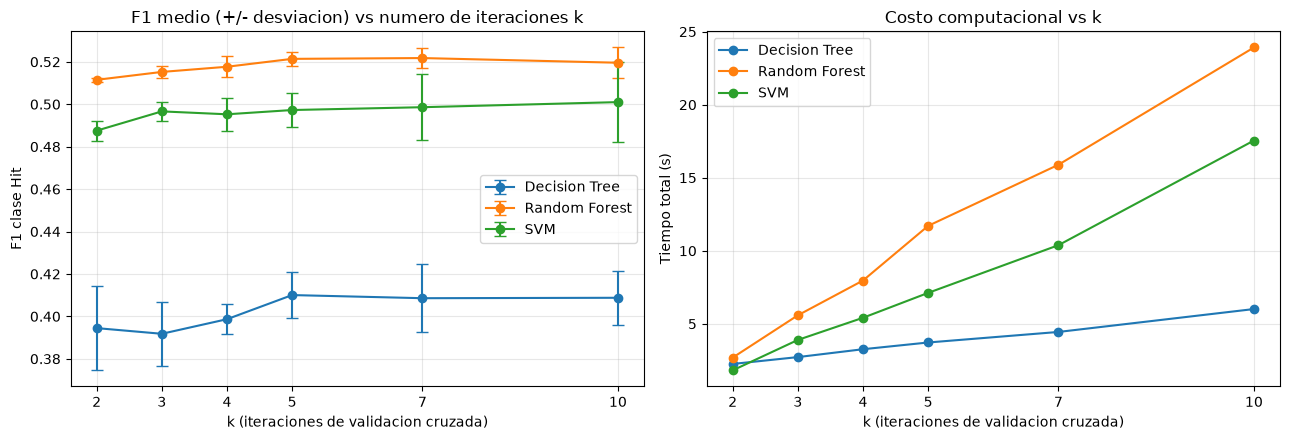

,Modelo,k,F1 medio,Desv. F1,Tiempo (s)
0,Decision Tree,2,0.3945,0.0199,2.2532
1,Decision Tree,3,0.3918,0.0150,2.7224
2,Decision Tree,4,0.3987,0.0071,3.2613
3,Decision Tree,5,0.4100,0.0107,3.7224
4,Decision Tree,7,0.4086,0.0159,4.4442
5,Decision Tree,10,0.4088,0.0128,6.0118
6,Random Forest,2,0.5115,0.0010,2.6865
7,Random Forest,3,0.5152,0.0029,5.5829
8,Random Forest,4,0.5177,0.0049,7.9646
9,Random Forest,5,0.5214,0.0034,11.7061


In [21]:
valores_k = [2, 3, 4, 5, 7, 10]

modelos_cv = {
    'Decision Tree': (DecisionTreeClassifier(max_depth=mejor_max_depth, class_weight='balanced',
                                             random_state=SEMILLA), X_train, y_train),
    'Random Forest': (RandomForestClassifier(n_estimators=mejor_n_estimators, class_weight='balanced',
                                             min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1),
                      X_train, y_train),
    'SVM': (make_pipeline(StandardScaler(), SVC(kernel=mejor_kernel, class_weight='balanced',
                                                cache_size=1000)), X_train_svm, y_train_svm),
}

resultados_k = []
for nombre, (modelo, X_cv, y_cv) in modelos_cv.items():
    for k in valores_k:
        cv_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEMILLA)
        inicio = time.time()
        scores = cross_val_score(modelo, X_cv, y_cv, cv=cv_k, scoring='f1',
                                 n_jobs=1 if nombre == 'Random Forest' else -1)
        resultados_k.append({'Modelo': nombre, 'k': k, 'F1 medio': scores.mean(),
                             'Desv. F1': scores.std(), 'Tiempo (s)': time.time() - inicio})

df_k = pd.DataFrame(resultados_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, grupo in df_k.groupby('Modelo', sort=False):
    axes[0].errorbar(grupo['k'], grupo['F1 medio'], yerr=grupo['Desv. F1'], marker='o',
                     capsize=4, label=nombre)
    axes[1].plot(grupo['k'], grupo['Tiempo (s)'], 'o-', label=nombre)
axes[0].set_title('F1 medio (+/- desviacion) vs numero de iteraciones k')
axes[0].set_xlabel('k (iteraciones de validacion cruzada)')
axes[0].set_ylabel('F1 clase Hit')
axes[1].set_title('Costo computacional vs k')
axes[1].set_xlabel('k (iteraciones de validacion cruzada)')
axes[1].set_ylabel('Tiempo total (s)')
for ax in axes:
    ax.set_xticks(valores_k)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

df_k.round(4)

**Analisis del numero de iteraciones (k):**
- **k = 2 subestima el desempeno**: cada modelo entrena con solo el 50% del train (Random Forest 0.512 con k = 2 vs 0.521 con k = 5; SVM 0.488 vs 0.497). Con k = 3 y k = 4 la estimacion sigue un poco por debajo.
- **De k = 5 en adelante la estimacion se estabiliza**: en Random Forest, k = 5, 7 y 10 dan 0.521, 0.522 y 0.520, y en Decision Tree 0.410, 0.409 y 0.409.
- **El costo crece linealmente con k**: en Random Forest, 10 s con k = 5 contra 24 s con k = 10, sin ganar precision en la estimacion.
- Con k grande la desviacion **aumenta** (SVM: 0.008 con k = 5 vs 0.019 con k = 10), porque cada particion de validacion es mas pequena y tiene menos Hits, lo que hace mas ruidoso el F1 de cada iteracion.
- **Numero de iteraciones elegido: k = 5.** Es el punto donde la estimacion ya es estable, con un costo y una variabilidad moderados. Esto confirma el `cv5` usado en las curvas de las secciones 15 a 17.

### 18.1 Curva de aprendizaje por tamano de entrenamiento (Random Forest)

Complementando lo anterior, la curva de aprendizaje clasica muestra como cambia el F1 de train y validacion (con k = 5) a medida que el modelo recibe mas datos. Permite diagnosticar si conseguir mas canciones ayudaria al modelo.

Tiempo: 33.4 s


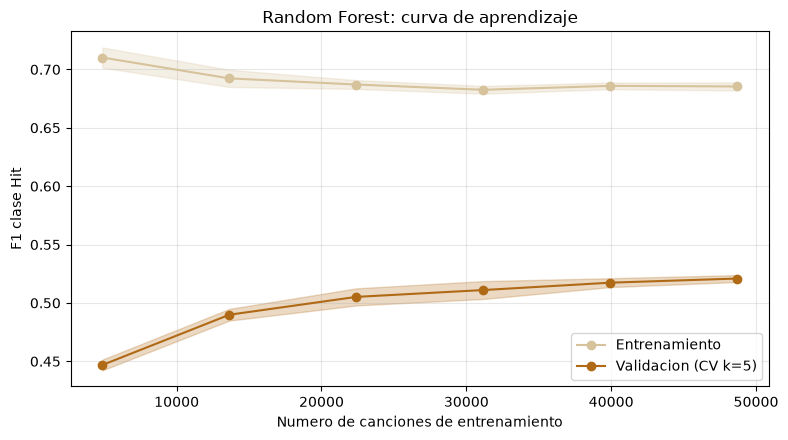

,Tamano train,F1 train,F1 validacion
0,4871,0.7102,0.4469
1,13639,0.6923,0.4899
2,22408,0.6871,0.5052
3,31176,0.6826,0.5111
4,39945,0.6859,0.5174
5,48714,0.6854,0.5209


In [22]:
inicio = time.time()
tamanos, lc_train, lc_val = learning_curve(
    RandomForestClassifier(n_estimators=mejor_n_estimators, class_weight='balanced',
                           min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1),
    X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 6), cv=cv5, scoring='f1', n_jobs=1)
print(f"Tiempo: {time.time() - inicio:.1f} s")

fig, ax = plt.subplots(figsize=(8, 4.5))
for scores, color, etiqueta in [(lc_train, COLOR_TRAIN, 'Entrenamiento'), (lc_val, COLOR_VAL, 'Validacion (CV k=5)')]:
    ax.plot(tamanos, scores.mean(axis=1), 'o-', color=color, label=etiqueta)
    ax.fill_between(tamanos, scores.mean(axis=1) - scores.std(axis=1),
                    scores.mean(axis=1) + scores.std(axis=1), color=color, alpha=0.25)
ax.set_xlabel('Numero de canciones de entrenamiento')
ax.set_ylabel('F1 clase Hit')
ax.set_title('Random Forest: curva de aprendizaje')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({'Tamano train': tamanos, 'F1 train': lc_train.mean(axis=1).round(4),
              'F1 validacion': lc_val.mean(axis=1).round(4)})

**Analisis de la curva de aprendizaje:** el F1 de validacion sube de 0.447 (con ~4,900 canciones) a 0.521 (con ~48,700), mientras que el de train baja levemente (0.71 -> 0.69). Las curvas se acercan pero siguen separadas, y la de validacion se va aplanando. Conseguir mas canciones ayudaria un poco, pero el limite principal no es la cantidad de datos sino la **informacion disponible**: con solo variables acusticas y genero no se sabe quien es el artista ni cuanta promocion tuvo la cancion (ver seccion 11).

## 19. Deep Learning — Perceptron multicapa (MLP)

Se construyen tres redes densas (*fully connected*) con TensorFlow / Keras:

| Red | Capas ocultas | Neuronas |
|---|---|---|
| MLP-3 | 3 | 64, 128, 128 |
| MLP-6 | 6 | 64, 64, 128, 128, 256, 256 |
| MLP-10 | 10 | 128 en todas |

**Configuracion comun:**
- Entrada: las variables escaladas con `StandardScaler`.
- Capas ocultas con activacion **ReLU**.
- Salida: **1 neurona con activacion sigmoide** (probabilidad de ser Hit); se clasifica como Hit si la probabilidad es mayor a 0.5.
- Perdida: entropia cruzada binaria. Optimizador: Adam (tasa de aprendizaje 0.001). Tamano de lote: 512.
- Pesos de clase balanceados (equivalente a `class_weight='balanced'` de sklearn).
- Del train se separa un 20% como **conjunto de validacion** para elegir arquitectura y epochs; el test sigue sin tocarse.

**Experimento de epochs:** cada arquitectura se entrena **desde cero** con 5, 10, 50 y 100 epochs (12 entrenamientos en total, todos con la misma semilla) y se mide el F1 sobre validacion.

In [23]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEMILLA)

# Particion de validacion interna (20% del train), estratificada
X_tr_dl, X_val_dl, y_tr_dl, y_val_dl = train_test_split(
    X_train_esc, y_train.values, test_size=0.20, stratify=y_train, random_state=SEMILLA)

# Pesos de clase balanceados para compensar la minoria de Hits
pesos = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_tr_dl)
pesos_clase = {0: float(pesos[0]), 1: float(pesos[1])}
print("Pesos de clase:", {k: round(v, 3) for k, v in pesos_clase.items()})

ARQUITECTURAS = {
    'MLP-3 (64,128,128)': [64, 128, 128],
    'MLP-6 (64,64,128,128,256,256)': [64, 64, 128, 128, 256, 256],
    'MLP-10 (128 x 10)': [128] * 10,
}
LISTA_EPOCHS = [5, 10, 50, 100]


def construir_mlp(capas_ocultas, n_entradas):
    # Red densa: entrada -> capas ocultas ReLU -> salida sigmoide
    modelo = keras.Sequential([layers.Input(shape=(n_entradas,))])
    for neuronas in capas_ocultas:
        modelo.add(layers.Dense(neuronas, activation='relu'))
    modelo.add(layers.Dense(1, activation='sigmoid'))
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='binary_crossentropy', metrics=['accuracy'])
    return modelo


construir_mlp(ARQUITECTURAS['MLP-3 (64,128,128)'], X_train_esc.shape[1]).summary()

Pesos de clase: {0: 0.585, 1: 3.442}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         8,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,089 (129.25 KB)

 Trainable params: 33,089 (129.25 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
resultados_dl = []
historiales = {}
modelos_dl = {}

for nombre, capas in ARQUITECTURAS.items():
    for n_epochs in LISTA_EPOCHS:
        # Misma semilla en cada experimento: la unica diferencia es el numero de epochs
        keras.utils.set_random_seed(SEMILLA)
        modelo = construir_mlp(capas, X_train_esc.shape[1])

        inicio = time.time()
        historial = modelo.fit(X_tr_dl, y_tr_dl, epochs=n_epochs, batch_size=512,
                               class_weight=pesos_clase, validation_data=(X_val_dl, y_val_dl),
                               verbose=0)
        duracion = time.time() - inicio

        pred_tr = (modelo.predict(X_tr_dl, verbose=0).ravel() > 0.5).astype(int)
        pred_val = (modelo.predict(X_val_dl, verbose=0).ravel() > 0.5).astype(int)

        resultados_dl.append({'Arquitectura': nombre, 'Epochs': n_epochs,
                              'F1 train': f1_score(y_tr_dl, pred_tr),
                              'F1 validacion': f1_score(y_val_dl, pred_val),
                              'Accuracy validacion': accuracy_score(y_val_dl, pred_val),
                              'Tiempo (s)': duracion})
        historiales[(nombre, n_epochs)] = historial.history
        modelos_dl[(nombre, n_epochs)] = modelo
        print(f"{nombre:32s} | epochs={n_epochs:3d} | F1 val={resultados_dl[-1]['F1 validacion']:.4f} | {duracion:.1f} s")

df_dl = pd.DataFrame(resultados_dl)

MLP-3 (64,128,128)               | epochs=  5 | F1 val=0.4849 | 3.1 s


MLP-3 (64,128,128)               | epochs= 10 | F1 val=0.4943 | 4.0 s


MLP-3 (64,128,128)               | epochs= 50 | F1 val=0.4918 | 15.5 s


MLP-3 (64,128,128)               | epochs=100 | F1 val=0.4818 | 29.0 s


MLP-6 (64,64,128,128,256,256)    | epochs=  5 | F1 val=0.4737 | 3.9 s


MLP-6 (64,64,128,128,256,256)    | epochs= 10 | F1 val=0.4790 | 6.4 s


... (2 outputs left out)

MLP-10 (128 x 10)                | epochs=  5 | F1 val=0.4849 | 5.6 s


MLP-10 (128 x 10)                | epochs= 10 | F1 val=0.4754 | 8.3 s


MLP-10 (128 x 10)                | epochs= 50 | F1 val=0.4925 | 34.3 s


MLP-10 (128 x 10)                | epochs=100 | F1 val=0.4614 | 64.4 s


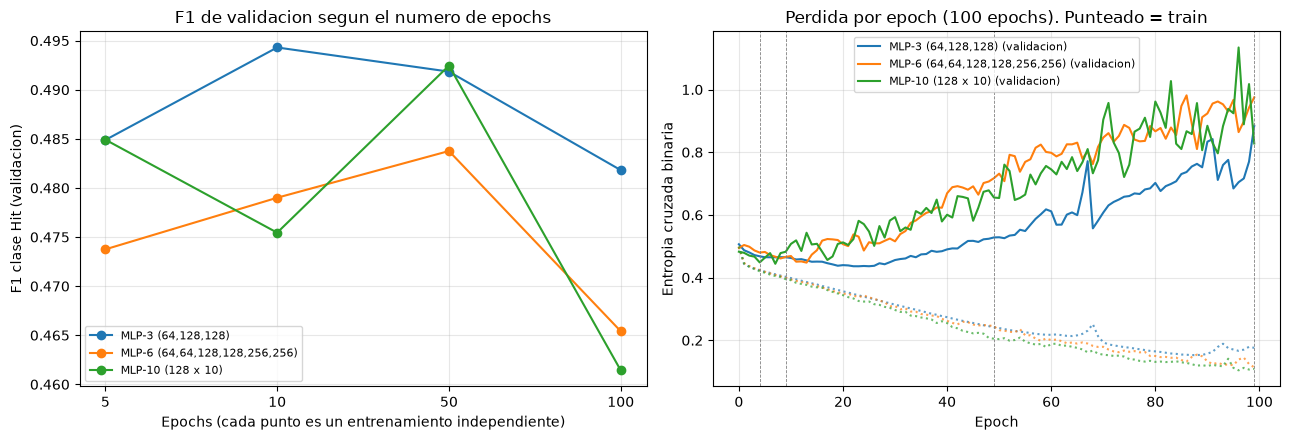

Epochs,5,10,50,100
Arquitectura,,,,
MLP-10 (128 x 10),0.4849,0.4754,0.4925,0.4614
"MLP-3 (64,128,128)",0.4849,0.4943,0.4918,0.4818
"MLP-6 (64,64,128,128,256,256)",0.4737,0.4790,0.4838,0.4654


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# F1 de validacion por numero de epochs para cada arquitectura
for nombre, grupo in df_dl.groupby('Arquitectura', sort=False):
    axes[0].plot(grupo['Epochs'].astype(str), grupo['F1 validacion'], 'o-', label=nombre)
axes[0].set_title('F1 de validacion segun el numero de epochs')
axes[0].set_xlabel('Epochs (cada punto es un entrenamiento independiente)')
axes[0].set_ylabel('F1 clase Hit (validacion)')
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

# Curvas de perdida del entrenamiento de 100 epochs: muestran donde empieza el sobreajuste
for nombre in ARQUITECTURAS:
    h = historiales[(nombre, 100)]
    linea, = axes[1].plot(h['val_loss'], label=f'{nombre} (validacion)')
    axes[1].plot(h['loss'], linestyle=':', color=linea.get_color(), alpha=0.7)
for ep in LISTA_EPOCHS:
    axes[1].axvline(ep - 1, color='gray', linewidth=0.6, linestyle='--')
axes[1].set_title('Perdida por epoch (100 epochs). Punteado = train')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Entropia cruzada binaria')
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

tabla_dl = df_dl.pivot(index='Arquitectura', columns='Epochs', values='F1 validacion').round(4)
tabla_dl

In [26]:
fila_mejor = df_dl.loc[df_dl['F1 validacion'].idxmax()]
mejor_arquitectura, mejores_epochs = fila_mejor['Arquitectura'], int(fila_mejor['Epochs'])
modelo_dl_final = modelos_dl[(mejor_arquitectura, mejores_epochs)]

print(f"Mejor red: {mejor_arquitectura} con {mejores_epochs} epochs")
print(f"F1 validacion: {fila_mejor['F1 validacion']:.4f} | F1 train: {fila_mejor['F1 train']:.4f}")
df_dl.round(4)

Mejor red: MLP-3 (64,128,128) con 10 epochs
F1 validacion: 0.4943 | F1 train: 0.5210


,Arquitectura,Epochs,F1 train,F1 validacion,Accuracy validacion,Tiempo (s)
0,"MLP-3 (64,128,128)",5,0.5037,0.4849,0.7355,3.1076
1,"MLP-3 (64,128,128)",10,0.5210,0.4943,0.7483,3.9687
2,"MLP-3 (64,128,128)",50,0.6755,0.4918,0.7927,15.5062
3,"MLP-3 (64,128,128)",100,0.6639,0.4818,0.7695,28.9784
4,"MLP-6 (64,64,128,128,256,256)",5,0.4926,0.4737,0.7152,3.9321
5,"MLP-6 (64,64,128,128,256,256)",10,0.5087,0.4790,0.7249,6.3705
6,"MLP-6 (64,64,128,128,256,256)",50,0.6283,0.4838,0.7611,28.8074
7,"MLP-6 (64,64,128,128,256,256)",100,0.8129,0.4654,0.8185,53.2653
8,MLP-10 (128 x 10),5,0.5065,0.4849,0.7350,5.5946
9,MLP-10 (128 x 10),10,0.5073,0.4754,0.7194,8.3403


**Analisis del experimento de epochs y arquitecturas:**
- **5 epochs:** los modelos quedan sub-entrenados (F1 validacion 0.474-0.485).
- **10 epochs:** el mejor resultado de todo el experimento, **MLP-3 con F1 = 0.494**.
- **50 epochs:** MLP-6 y MLP-10 alcanzan aqui su maximo (0.484 y 0.493), pero sin superar al MLP-3 con 10 epochs, y a un costo 4 a 9 veces mayor.
- **100 epochs:** es el **peor** valor para las tres redes (0.461-0.482). La grafica de perdida lo explica: la perdida de validacion es minima alrededor de los epochs 10-20 y despues **sube**, mientras la de entrenamiento sigue bajando. Es *overfitting*: el F1 de train de MLP-10 llega a 0.85 mientras el de validacion cae a 0.46.
- **Mas capas no significa mejor desempeno:** para datos tabulares con 126 variables, las redes de 6 y 10 capas tienen muchos mas parametros y solo memorizan mas rapido el entrenamiento.

**Eleccion: MLP-3 (64, 128, 128) con 10 epochs.** Tiene el mayor F1 de validacion, el menor riesgo de sobreajuste (train 0.521 vs validacion 0.494) y el menor costo (~4 s de entrenamiento).

## 20. Comparacion final sobre el conjunto de prueba

Cada modelo se entrena con su mejor configuracion y se evalua **una sola vez** sobre el 20% de prueba que no se uso en ninguna decision anterior:

- **Decision Tree** y **Random Forest:** entrenados con todo el train.
- **SVM:** entrenado con una submuestra estratificada de 20,000 canciones del train (por costo computacional, ver seccion 17).
- **Deep Learning:** la mejor red de la seccion 19 (entrenada con el 80% del train).

Se reportan F1, precision y recall de la clase Hit, ademas de accuracy y *balanced accuracy* (promedio del recall de ambas clases).

In [27]:
modelos_finales = {}

inicio = time.time()
modelos_finales['Decision Tree'] = DecisionTreeClassifier(
    max_depth=mejor_max_depth, class_weight='balanced', random_state=SEMILLA).fit(X_train, y_train)

modelos_finales['Random Forest'] = RandomForestClassifier(
    n_estimators=mejor_n_estimators, class_weight='balanced', min_samples_leaf=5,
    random_state=SEMILLA, n_jobs=-1).fit(X_train, y_train)

X_train_svm_final, _, y_train_svm_final, _ = train_test_split(
    X_train, y_train, train_size=20000, stratify=y_train, random_state=SEMILLA)
modelos_finales['SVM'] = make_pipeline(
    StandardScaler(), SVC(kernel=mejor_kernel, class_weight='balanced', cache_size=1000)
).fit(X_train_svm_final, y_train_svm_final)
print(f"Tiempo de entrenamiento final: {time.time() - inicio:.1f} s")

predicciones = {nombre: m.predict(X_test) for nombre, m in modelos_finales.items()}
predicciones['Deep Learning (MLP)'] = (modelo_dl_final.predict(X_test_esc, verbose=0).ravel() > 0.5).astype(int)

metricas = pd.DataFrame({
    nombre: {'F1 (Hit)': f1_score(y_test, pred),
             'Precision (Hit)': precision_score(y_test, pred),
             'Recall (Hit)': recall_score(y_test, pred),
             'Accuracy': accuracy_score(y_test, pred),
             'Balanced accuracy': balanced_accuracy_score(y_test, pred)}
    for nombre, pred in predicciones.items()}).T

metricas.round(4)

Tiempo de entrenamiento final: 27.1 s


,F1 (Hit),Precision (Hit),Recall (Hit),Accuracy,Balanced accuracy
Decision Tree,0.4226,0.3042,0.6917,0.7241,0.7107
Random Forest,0.5207,0.4109,0.7106,0.8091,0.7682
SVM,0.4968,0.3518,0.8452,0.7501,0.7895
Deep Learning (MLP),0.5032,0.3554,0.8614,0.7517,0.7972


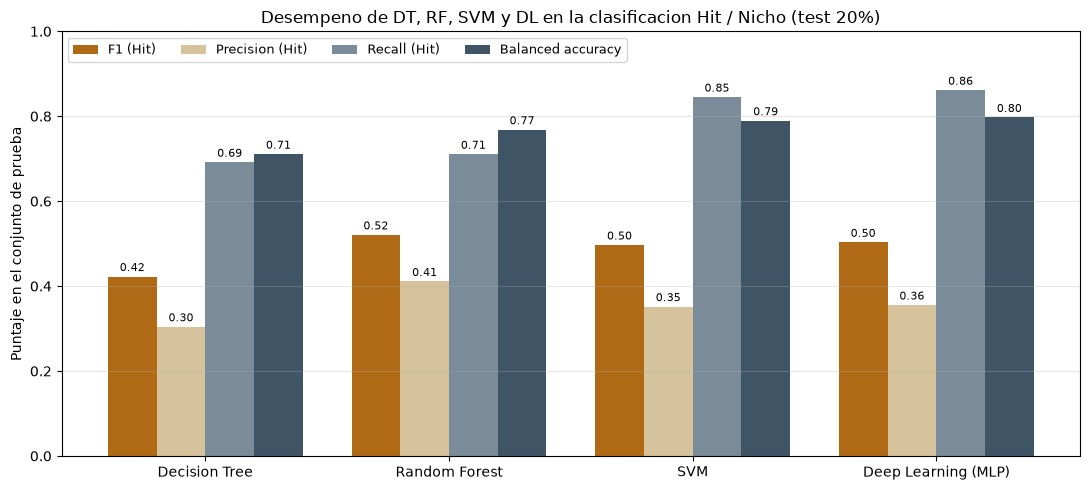

In [28]:
# Barplot final del desempeno de DT, RF, SVM y DL sobre el conjunto de prueba
metricas_graficar = ['F1 (Hit)', 'Precision (Hit)', 'Recall (Hit)', 'Balanced accuracy']
colores_metricas = ['#B06A16', '#D6C29B', '#7A8B99', '#3F5566']

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(metricas))
ancho = 0.2
for i, (metrica, color) in enumerate(zip(metricas_graficar, colores_metricas)):
    barras = ax.bar(x + (i - 1.5) * ancho, metricas[metrica], ancho, label=metrica, color=color)
    ax.bar_label(barras, fmt='%.2f', fontsize=8, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(metricas.index)
ax.set_ylim(0, 1)
ax.set_ylabel('Puntaje en el conjunto de prueba')
ax.set_title('Desempeno de DT, RF, SVM y DL en la clasificacion Hit / Nicho (test 20%)')
ax.legend(loc='upper left', ncol=4, fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

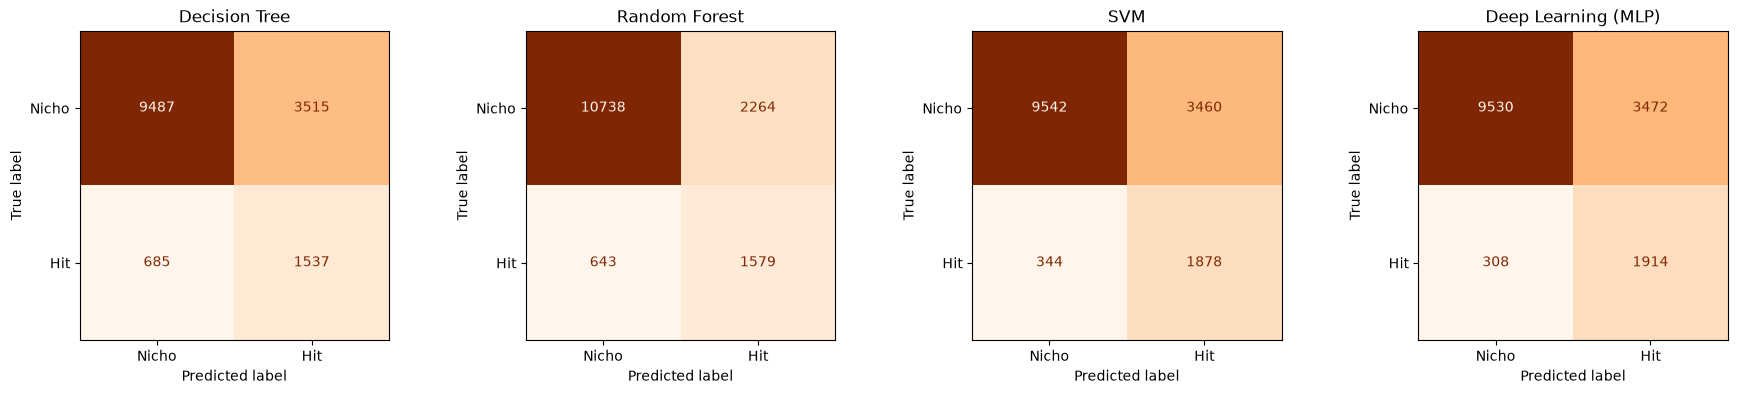

Reporte de clasificacion del mejor modelo (Random Forest):
              precision    recall  f1-score   support

       Nicho       0.94      0.83      0.88     13002
         Hit       0.41      0.71      0.52      2222

    accuracy                           0.81     15224
   macro avg       0.68      0.77      0.70     15224
weighted avg       0.87      0.81      0.83     15224



In [29]:
# Matrices de confusion de los cuatro modelos
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nombre, pred) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Nicho', 'Hit'],
                                            cmap='Oranges', colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

mejor_modelo = metricas['F1 (Hit)'].idxmax()
print(f"Reporte de clasificacion del mejor modelo ({mejor_modelo}):")
print(classification_report(y_test, predicciones[mejor_modelo], target_names=['Nicho', 'Hit']))

## Conclusiones de la Entrega 2

| Modelo | Configuracion elegida | F1 (Hit) | Precision | Recall | Balanced acc. |
|---|---|---|---|---|---|
| Decision Tree | `max_depth = 60` | 0.42 | 0.30 | 0.69 | 0.71 |
| **Random Forest** | `n_estimators = 100` | **0.52** | **0.41** | 0.71 | 0.77 |
| SVM | `kernel = poly` | 0.50 | 0.35 | 0.85 | 0.79 |
| Deep Learning | MLP-3, 10 epochs | 0.50 | 0.36 | **0.86** | **0.80** |

1. **Random Forest es el mejor modelo segun la metrica principal (F1 = 0.52)** y el que tiene mejor precision: cuando dice "Hit", acierta el 41% de las veces, frente a ~35% del SVM y la red. Ademas es rapido, no necesita escalado y entrega importancia de variables para explicar las predicciones en la aplicacion web. Se confirma como el clasificador del pipeline, tal como se planteo en la arquitectura.
2. **SVM y la red neuronal son mas "agresivos"**: detectan el 85-86% de los Hits reales (mayor recall y *balanced accuracy*) a cambio de mas falsos positivos. Si al producto le importara no dejar escapar ningun Hit potencial, la MLP seria una alternativa valida.
3. **El Decision Tree individual es el mas debil**, lo que muestra en la practica la ventaja del ensamble (Random Forest) sobre un solo arbol.
4. **La accuracy no sirve como metrica aqui.** Todos los modelos tienen accuracy menor al 85% que lograria un clasificador que siempre diga "Nicho". Esto es esperado: con `class_weight='balanced'` los modelos sacrifican aciertos en la clase mayoritaria para encontrar Hits, que es el objetivo.
5. **Techo de desempeno (F1 ~0.5):** los cuatro modelos, aunque son muy distintos entre si, llegan a valores parecidos. Eso indica que el limite esta en los **datos** y no en el algoritmo: el audio y el genero explican solo una parte de la popularidad. Esto coincide con la limitacion documentada en la seccion 11 y en la literatura de *Music Information Retrieval*. La siguiente entrega medira cuanto mejora el modo "Cancion existente" al agregar `artist_avg_popularity`, que en la Entrega 1 mostro una correlacion de 0.66 con la popularidad.

---
# ENTREGA 3 — Aprendizaje no supervisado: clustering acustico

## 21. Planteamiento del problema no supervisado

En las entregas anteriores el modelo aprendia a partir de una etiqueta (Hit / Nicho). Ahora el objetivo es distinto: **descubrir grupos de canciones con un perfil acustico parecido sin usar ninguna etiqueta**. Este es el primer bloque del pipeline en cascada de AudioMetrics (el "cluster acustico" de la cancion).

**Variables de entrada:** las 10 variables acusticas continuas analizadas en la seccion 8 (`danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`, `duration_ms`), sobre las 76,117 canciones de la matriz de modelado (sin duplicados, seccion 13).

- Se excluyen las 113 columnas One-Hot de genero: son variables binarias y muy dispersas (cada una vale 1 en menos del 1% de las canciones). En la seccion 23 se muestra que, si se incluyen, el PCA a 2 componentes conserva solo el 4% de la informacion.
- Se excluyen `key`, `mode`, `time_signature` y `explicit`: son categoricas o binarias, y la distancia euclidiana (que usan K-Means y DBSCAN) no tiene sentido sobre ellas. Por ejemplo, la tonalidad 11 (Si) no esta "mas lejos" de la 0 (Do) que la 1 (Do#).
- Se excluye `popularity`: es la variable que el pipeline quiere predecir.

**La clase real (Hit / Nicho) no se usa para agrupar.** Solo se usa al final para comparar los grupos encontrados con las clases reales (grafica "original").

**Mapa de los requisitos de la Entrega 3 en este notebook:**

| Requisito | Seccion |
|---|---|
| 1. Escalado de los datos (StandardScaler o MinMaxScaler) | 22 |
| 2. Reduccion con PCA a 2 componentes | 23 |
| 3. K-Means con `n_clusters` <= numero de clases | 24 |
| 4. DBSCAN: busqueda y justificacion de `eps` y `min_samples` | 25 |
| 5. Graficas: original, K-Means y DBSCAN | 26 |

In [30]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Paleta de las graficas de clustering (validada para distintos tipos de daltonismo)
COLOR_AZUL = '#2F6DB5'
COLOR_AMBAR = '#B06A16'
COLOR_VERDE = '#2E9C7A'
COLOR_RUIDO = '#9AA0A6'

# Variables de entrada: las 10 variables acusticas continuas de la seccion 8
X_clu = X[variables_acusticas].copy()

# Clase real de cada cancion con el mismo corte de la Entrega 2 (solo para comparar al final)
clase_real = (popularidad > corte_hit).astype(int).values

# Genero de cada cancion reconstruido desde el One-Hot (la categoria eliminada por drop_first es 'acoustic')
columnas_genero = [c for c in X.columns if c.startswith('track_genre_')]
genero = X[columnas_genero].idxmax(axis=1).str.replace('track_genre_', '', regex=False)
genero[X[columnas_genero].sum(axis=1) == 0] = 'acoustic'

print(f"Canciones: {X_clu.shape[0]:,} | Variables de entrada: {X_clu.shape[1]}")
print(f"Proporcion de Hits (solo para comparar): {clase_real.mean()*100:.2f}%")
X_clu.describe().T.round(3)

Canciones: 76,117 | Variables de entrada: 10
Proporcion de Hits (solo para comparar): 14.54%


,count,mean,std,min,25%,50%,75%,max
danceability,76117.0,0.577,0.164,0.051,0.471,0.586,0.696,0.985
energy,76117.0,0.669,0.228,0.000,0.500,0.702,0.865,1.000
loudness,76117.0,-7.425,3.396,-17.285,-9.443,-6.813,-4.906,1.864
speechiness,76117.0,0.089,0.112,0.022,0.036,0.050,0.090,0.963
acousticness,76117.0,0.296,0.315,0.000,0.015,0.161,0.555,0.996
instrumentalness,76117.0,0.129,0.281,0.000,0.000,0.000,0.019,0.999
liveness,76117.0,0.219,0.194,0.009,0.099,0.137,0.286,1.000
valence,76117.0,0.491,0.255,0.000,0.284,0.483,0.695,0.995
tempo,76117.0,123.379,29.272,37.490,100.007,122.961,142.003,204.702
duration_ms,76117.0,217204.108,64166.557,43000.000,174540.000,212453.000,256500.000,392656.000


## 22. Escalado de los datos: StandardScaler vs. MinMaxScaler

PCA, K-Means y DBSCAN trabajan con **distancias y varianzas**, asi que son muy sensibles a la escala. Sin escalar, `duration_ms` (valores de ~200,000) dominaria por completo frente a `danceability` (entre 0 y 1), y el resultado dependeria solo de la duracion.

Las dos opciones planteadas:
- **StandardScaler:** `z = (x - media) / desviacion`. Cada variable queda con media 0 y desviacion 1.
- **MinMaxScaler:** `z = (x - min) / (max - min)`. Cada variable queda en el rango [0, 1].

Para decidir, se mide **cuanto pesa cada variable despues de escalar**. PCA busca las direcciones de mayor varianza, asi que una variable con mas varianza tiene mas influencia en los componentes.

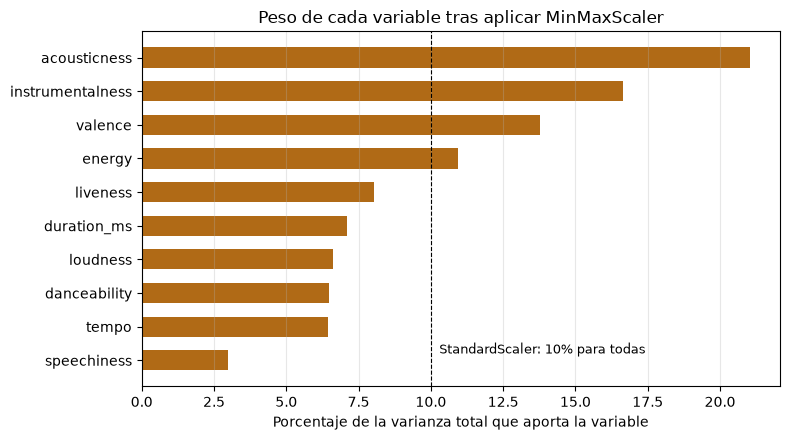

,Asimetria (datos originales),Desv. tras MinMaxScaler,Peso % con MinMaxScaler,Peso % con StandardScaler
speechiness,4.342,0.119,2.979,10.0
tempo,0.288,0.175,6.447,10.0
danceability,-0.310,0.175,6.478,10.0
loudness,-0.677,0.177,6.615,10.0
duration_ms,0.249,0.184,7.085,10.0
liveness,2.030,0.195,8.025,10.0
energy,-0.482,0.228,10.925,10.0
valence,0.088,0.256,13.773,10.0
instrumentalness,2.020,0.281,16.651,10.0
acousticness,0.759,0.316,21.023,10.0


In [31]:
X_std = StandardScaler().fit_transform(X_clu)
X_mm = MinMaxScaler().fit_transform(X_clu)

# Porcentaje de la varianza total que aporta cada variable tras cada escalado
peso_std = X_std.var(axis=0) / X_std.var(axis=0).sum() * 100
peso_mm = X_mm.var(axis=0) / X_mm.var(axis=0).sum() * 100

tabla_escalado = pd.DataFrame({
    'Asimetria (datos originales)': X_clu.skew().values,
    'Desv. tras MinMaxScaler': X_mm.std(axis=0),
    'Peso % con MinMaxScaler': peso_mm,
    'Peso % con StandardScaler': peso_std,
}, index=variables_acusticas).sort_values('Peso % con MinMaxScaler')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(tabla_escalado.index, tabla_escalado['Peso % con MinMaxScaler'], color=COLOR_AMBAR, height=0.6)
ax.axvline(10, color='black', linestyle='--', linewidth=0.8)
ax.annotate('StandardScaler: 10% para todas', xy=(10, 0.2), xytext=(6, 0), textcoords='offset points', fontsize=9)
ax.set_xlabel('Porcentaje de la varianza total que aporta la variable')
ax.set_title('Peso de cada variable tras aplicar MinMaxScaler')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

tabla_escalado.round(3)

**Analisis del escalado:**
- Con **MinMaxScaler** el peso de cada variable depende de la **forma de su distribucion**, no de su importancia. `acousticness` aporta el 21% de la varianza y `instrumentalness` el 16.7%, porque son bimodales (muchas canciones cerca de 0 y muchas cerca de 1). En cambio, `speechiness` aporta solo el 3%: unas pocas canciones habladas (rap, *spoken word*) fijan el maximo en 0.96, mientras la mediana es 0.05, asi que el resto queda comprimido cerca de 0 (asimetria de 4.3). Entre la variable que mas pesa y la que menos hay una diferencia de 7 veces.
- Con **StandardScaler** cada variable aporta exactamente el **10%** de la varianza: todas entran al PCA y al calculo de distancias en igualdad de condiciones.
- MinMaxScaler tambien depende solo de dos valores (el minimo y el maximo), asi que una sola cancion extrema cambia la escala de toda la variable. StandardScaler usa la media y la desviacion de todas las canciones.

**Escalador elegido: StandardScaler.** Ademas, es el mismo escalado que se uso para el SVM y la red neuronal en la Entrega 2.

## 23. Reduccion de dimensionalidad con PCA: 10 variables -> 2 componentes

El Analisis de Componentes Principales (PCA) construye nuevas variables (**componentes**) como combinaciones lineales de las originales, ordenadas segun cuanta varianza explican. Con 2 componentes cada cancion se convierte en un punto en un plano que se puede graficar, perdiendo la menor cantidad de informacion posible.

Primero se compara el PCA con las 126 variables de la matriz de modelado (acusticas + genero) contra el PCA con las 10 variables acusticas, para justificar la eleccion de la seccion 21.

                                    Variables de entrada  Varianza PC1 (%)  Varianza PC2 (%)  Varianza total 2 comp. (%)
126 variables (acusticas + genero)                   126              2.44              1.79                        4.23
10 variables acusticas                                10             24.62             16.48                       41.10


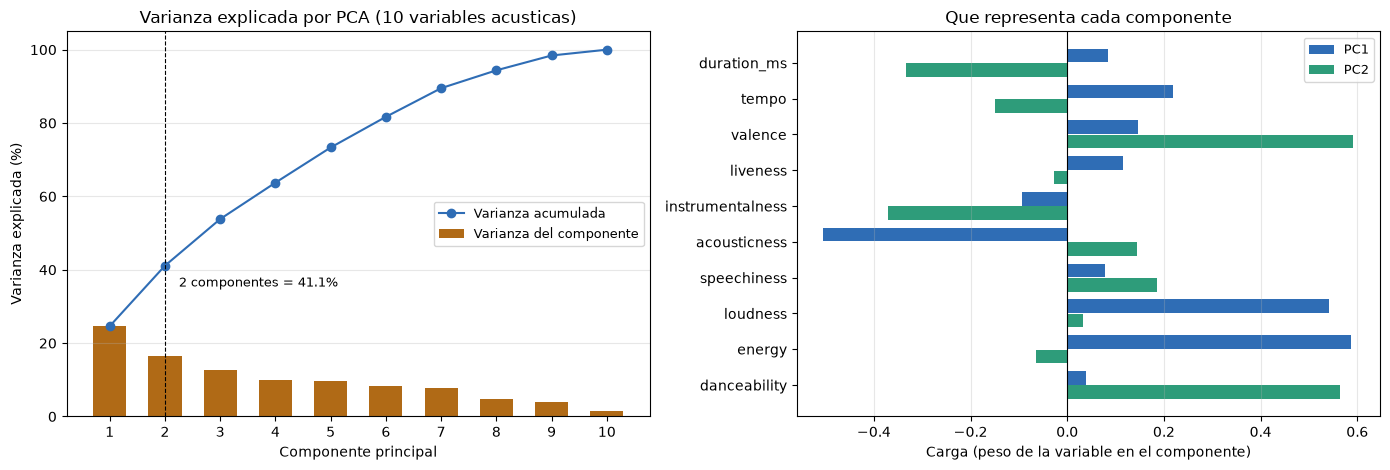

,PC1,PC2
danceability,0.040,0.563
energy,0.588,-0.065
loudness,0.541,0.032
speechiness,0.079,0.185
acousticness,-0.505,0.144
instrumentalness,-0.094,-0.370
liveness,0.114,-0.028
valence,0.146,0.592
tempo,0.220,-0.150
duration_ms,0.085,-0.334


In [32]:
# PCA con todas las variables de la Entrega 2 (126 columnas, incluido el One-Hot de genero)
pca_126 = PCA(n_components=2, random_state=SEMILLA).fit(StandardScaler().fit_transform(X))

# PCA final: 10 variables acusticas escaladas -> 2 componentes
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X_std)

# PCA completo de las 10 variables, solo para ver la varianza de todos los componentes
pca_completo = PCA(random_state=SEMILLA).fit(X_std)

print(pd.DataFrame({
    'Variables de entrada': [X.shape[1], X_clu.shape[1]],
    'Varianza PC1 (%)': [pca_126.explained_variance_ratio_[0] * 100, pca.explained_variance_ratio_[0] * 100],
    'Varianza PC2 (%)': [pca_126.explained_variance_ratio_[1] * 100, pca.explained_variance_ratio_[1] * 100],
    'Varianza total 2 comp. (%)': [pca_126.explained_variance_ratio_.sum() * 100, pca.explained_variance_ratio_.sum() * 100],
}, index=['126 variables (acusticas + genero)', '10 variables acusticas']).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Varianza explicada por cada componente y acumulada
componentes = np.arange(1, len(pca_completo.explained_variance_ratio_) + 1)
axes[0].bar(componentes, pca_completo.explained_variance_ratio_ * 100, color=COLOR_AMBAR, width=0.6,
            label='Varianza del componente')
axes[0].plot(componentes, np.cumsum(pca_completo.explained_variance_ratio_) * 100, 'o-', color=COLOR_AZUL,
             label='Varianza acumulada')
axes[0].axvline(2, color='black', linestyle='--', linewidth=0.8)
axes[0].annotate(f'2 componentes = {pca.explained_variance_ratio_.sum()*100:.1f}%',
                 xy=(2, pca.explained_variance_ratio_.sum() * 100), xytext=(10, -15),
                 textcoords='offset points', fontsize=9)
axes[0].set_xticks(componentes)
axes[0].set_xlabel('Componente principal')
axes[0].set_ylabel('Varianza explicada (%)')
axes[0].set_title('Varianza explicada por PCA (10 variables acusticas)')
axes[0].set_ylim(0, 105)
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3)

# Cargas (pesos) de cada variable en PC1 y PC2
cargas = pd.DataFrame(pca.components_.T, index=variables_acusticas, columns=['PC1', 'PC2'])
y_pos = np.arange(len(cargas))
axes[1].barh(y_pos + 0.2, cargas['PC1'], height=0.38, color=COLOR_AZUL, label='PC1')
axes[1].barh(y_pos - 0.2, cargas['PC2'], height=0.38, color=COLOR_VERDE, label='PC2')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(cargas.index)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('Carga (peso de la variable en el componente)')
axes[1].set_title('Que representa cada componente')
axes[1].legend(fontsize=9)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

cargas.round(3)

**Analisis del PCA:**
- **Con las 126 variables, los 2 componentes conservan solo el 4.2% de la varianza.** Las 113 columnas de genero son binarias y casi independientes entre si, y cada una aporta su propia direccion de varianza. Un plano con el 4% de la informacion no representa los datos. Esto confirma que conviene usar solo las 10 variables acusticas.
- **Con las 10 variables acusticas, los 2 componentes conservan el 41.1% de la varianza** (PC1 = 24.6%, PC2 = 16.5%). La varianza esta repartida: hacen falta 7 componentes para llegar a ~90%, porque las variables acusticas miden cosas bastante distintas entre si. El plano 2D es una simplificacion util, pero no es todo el espacio acustico.
- **PC1 = "energia / sonoridad":** cargas altas de `energy` (+0.59) y `loudness` (+0.54), y negativa de `acousticness` (-0.51). A la izquierda quedan las canciones acusticas y suaves; a la derecha, las energeticas y fuertes.
- **PC2 = "bailabilidad / positividad":** cargas altas de `valence` (+0.59) y `danceability` (+0.56), y negativas de `instrumentalness` (-0.37) y `duration_ms` (-0.33). Arriba quedan las canciones cortas, bailables y alegres; abajo, las largas e instrumentales.

## 24. K-Means con `n_clusters` = numero de clases

K-Means divide los datos en *k* grupos: ubica *k* centroides y asigna cada cancion al centroide mas cercano, moviendo los centroides hasta que la suma de distancias al cuadrado (inercia) deja de bajar.

**Eleccion de `n_clusters`:** el requisito pide `n_clusters` <= numero de clases del dataset. El problema supervisado de la Entrega 2 tiene **2 clases (Hit / Nicho)**, asi que se usa `n_clusters = 2` (con 1 cluster no habria agrupacion). Asi se puede verificar si la estructura acustica de los datos coincide con las clases.

K-Means se aplica sobre las 2 componentes del PCA. Se usa `n_init=10` (10 inicializaciones distintas, se queda con la de menor inercia) para no depender de una mala posicion inicial de los centroides.

**Metricas:**
- **Silueta** (de -1 a 1): que tan separado esta cada punto de los otros clusters comparado con su propio cluster. Mayor a 0.5 indica grupos bien separados, entre 0.25 y 0.5 una estructura moderada. Se calcula sobre una muestra de 10,000 canciones por costo computacional.
- **ARI** (*Adjusted Rand Index*): concordancia entre los clusters y las clases reales. 1 = identicos, 0 = no mas parecido que una asignacion al azar.

In [33]:
N_CLASES = len(np.unique(clase_real))
print("Numero de clases del dataset (Hit / Nicho):", N_CLASES)

inicio = time.time()
kmeans = KMeans(n_clusters=N_CLASES, n_init=10, random_state=SEMILLA).fit(X_pca)
etiquetas_km = kmeans.labels_
print(f"Tiempo: {time.time() - inicio:.1f} s")

sil_km = silhouette_score(X_pca, etiquetas_km, sample_size=10000, random_state=SEMILLA)
ari_km = adjusted_rand_score(clase_real, etiquetas_km)
print(f"Silueta: {sil_km:.3f} | ARI frente a Hit/Nicho: {ari_km:.4f}")

# Tamano de cada cluster y proporcion de Hits dentro de el
resumen_km = pd.DataFrame({
    'Canciones': pd.Series(etiquetas_km).value_counts().sort_index(),
    '% del dataset': pd.Series(etiquetas_km).value_counts(normalize=True).sort_index() * 100,
    '% de Hits en el cluster': pd.Series(clase_real).groupby(etiquetas_km).mean() * 100,
})
resumen_km.index.name = 'Cluster K-Means'
print(resumen_km.round(2).to_string())

# Perfil acustico de cada cluster: mediana de cada variable en sus unidades originales
perfil_km = X_clu.groupby(etiquetas_km).median().T
perfil_km.columns = [f'Cluster {k}' for k in perfil_km.columns]
perfil_km['Mediana global'] = X_clu.median()
perfil_km.round(3)

Numero de clases del dataset (Hit / Nicho): 2
Tiempo: 0.1 s


Silueta: 0.402 | ARI frente a Hit/Nicho: -0.0096
                 Canciones  % del dataset  % de Hits en el cluster
Cluster K-Means                                                   
0                    50450          66.28                    15.31
1                    25667          33.72                    13.02


,Cluster 0,Cluster 1,Mediana global
danceability,0.594,0.570,0.586
energy,0.814,0.422,0.702
loudness,-5.562,-10.474,-6.813
speechiness,0.057,0.039,0.050
acousticness,0.048,0.671,0.161
instrumentalness,0.000,0.000,0.000
liveness,0.155,0.120,0.137
valence,0.531,0.391,0.483
tempo,126.946,112.014,122.961
duration_ms,216360.000,201689.000,212453.000


**Analisis de K-Means (n_clusters = 2):**
- **Cluster 0 - "energeticas" (50,450 canciones, 66%):** `energy` mediana 0.81, `loudness` -5.6 dB, `acousticness` 0.05 y `tempo` 127 BPM.
- **Cluster 1 - "acusticas / tranquilas" (25,667 canciones, 34%):** `energy` 0.42, `loudness` -10.5 dB, `acousticness` 0.67 y `tempo` 112 BPM.
- Los dos centroides quedan a la misma altura en PC2 y separados en PC1: **K-Means divide los datos segun el eje de energia**, que es el de mayor varianza.
- **Silueta = 0.40:** estructura moderada. Los grupos se distinguen, pero no hay un espacio vacio entre ellos (ver seccion 26).
- **ARI = -0.01 frente a Hit / Nicho:** los clusters no tienen ninguna relacion con las clases reales. El porcentaje de Hits es practicamente igual en ambos (15.3% y 13.0%, contra 14.5% en todo el dataset). Hay Hits tanto entre las canciones energeticas como entre las acusticas.

**Conclusion:** el perfil acustico no determina si una cancion es Hit. Esto coincide con el techo de F1 ~0.5 de la Entrega 2. El cluster sirve en la aplicacion para describir el **tipo de sonido** de la cancion, no para predecir su popularidad.

## 25. DBSCAN: busqueda de `eps` y `min_samples`

DBSCAN agrupa por **densidad**. No recibe el numero de clusters: los descubre. Tiene dos hiperparametros:

- **`eps`:** el radio del vecindario de cada punto.
- **`min_samples`:** cuantos puntos (incluido el mismo) debe haber dentro de ese radio para que un punto sea **nucleo** (*core point*).

Los puntos nucleo que estan a menos de `eps` entre si forman un mismo cluster. Los puntos que no son nucleo pero estan cerca de uno quedan en su cluster (puntos *borde*), y el resto se marca como **ruido** (etiqueta -1). A diferencia de K-Means, DBSCAN puede encontrar grupos de cualquier forma y **no obliga a que cada cancion pertenezca a un grupo**.

Los dos hiperparametros dependen el uno del otro, por eso se buscan en este orden:
1. Se fija un valor de `min_samples`.
2. Para ese valor se busca `eps` con la **curva de k-distancia** (metodo de Ester et al., 1996, autores de DBSCAN): para cada cancion se calcula la distancia a su vecino numero `min_samples` y se ordenan de menor a mayor. La mayoria de los puntos estan en zonas densas (distancias pequenas) y la curva sube de golpe en los puntos aislados. **El codo de la curva es el `eps` que separa los puntos densos del ruido.**
3. Se repite para varios `min_samples` y se comparan los resultados.

El codo se calcula de forma objetiva: se normalizan ambos ejes a [0, 1] y se toma el punto de la curva mas alejado de la recta que une sus extremos.

**Punto de partida para `min_samples`:** la regla practica de la literatura (Sander et al., 1998) es `min_samples = 2 x dimensiones = 4` para datos en 2D. Esa regla esta pensada para datasets pequenos; con 76 mil canciones conviene probar valores mayores, por eso se evaluan 4, 10, 20, 50 y 100.

Tiempo vecinos: 0.9 s


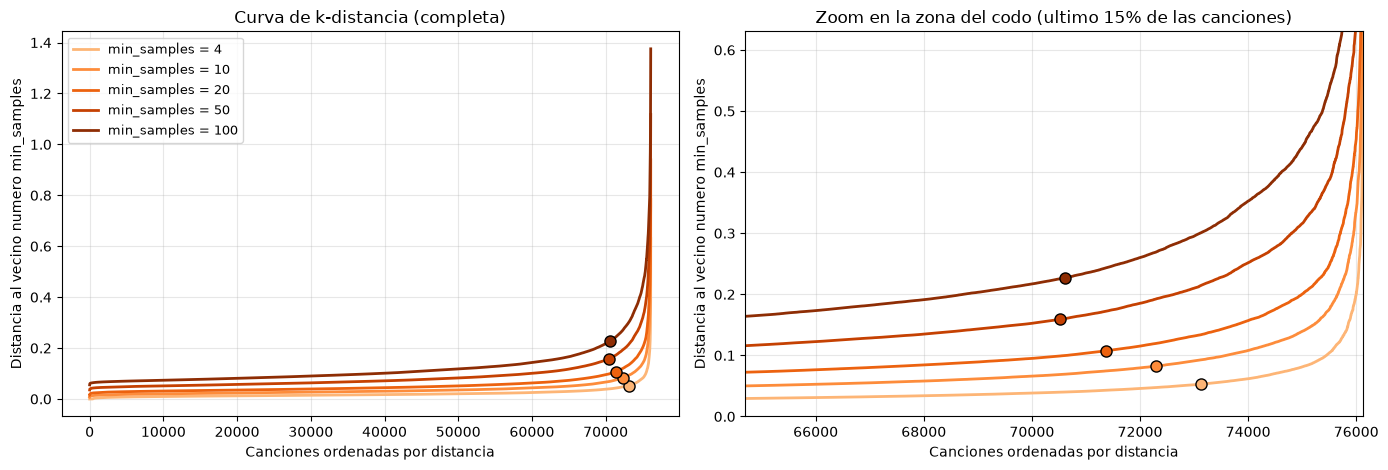

,eps (codo),Percentil del codo,Clusters,% ruido,% en el cluster mayor,Tamano mediano de los demas
min_samples,,,,,,
4,0.053,96.078,246,2.671,94.816,5.0
10,0.082,94.971,39,3.340,95.835,13.5
20,0.107,93.764,12,4.341,95.282,24.0
50,0.159,92.644,4,4.879,94.987,32.0
100,0.227,92.778,1,4.484,95.516,NaN


In [34]:
VALORES_MIN_SAMPLES = [4, 10, 20, 50, 100]


def codo_curva(valores_ordenados):
    # Punto de la curva mas alejado de la recta que une sus extremos (ejes normalizados a [0, 1])
    x = np.linspace(0, 1, len(valores_ordenados))
    y = (valores_ordenados - valores_ordenados.min()) / (valores_ordenados.max() - valores_ordenados.min())
    return int(np.argmax(x - y))


# Distancias a los 100 vecinos mas cercanos de cada cancion (el vecino 0 es la propia cancion,
# igual que en DBSCAN, donde min_samples cuenta al propio punto)
inicio = time.time()
distancias, _ = NearestNeighbors(n_neighbors=max(VALORES_MIN_SAMPLES)).fit(X_pca).kneighbors(X_pca)
print(f"Tiempo vecinos: {time.time() - inicio:.1f} s")

tonos = plt.cm.Oranges(np.linspace(0.35, 0.95, len(VALORES_MIN_SAMPLES)))
eps_codo = {}
filas_codo = []

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for (m, tono) in zip(VALORES_MIN_SAMPLES, tonos):
    k_dist = np.sort(distancias[:, m - 1])
    i_codo = codo_curva(k_dist)
    eps_codo[m] = round(float(k_dist[i_codo]), 3)
    for ax in axes:
        ax.plot(k_dist, color=tono, linewidth=2, label=f'min_samples = {m}')
        ax.plot(i_codo, k_dist[i_codo], 'o', color=tono, markersize=8, markeredgecolor='black')

    # DBSCAN con el eps del codo para este min_samples
    etiquetas = DBSCAN(eps=eps_codo[m], min_samples=m).fit_predict(X_pca)
    tamanos = np.bincount(etiquetas[etiquetas >= 0])
    filas_codo.append({'min_samples': m, 'eps (codo)': eps_codo[m],
                       'Percentil del codo': i_codo / len(k_dist) * 100,
                       'Clusters': len(tamanos),
                       '% ruido': (etiquetas == -1).mean() * 100,
                       '% en el cluster mayor': tamanos.max() / len(etiquetas) * 100,
                       'Tamano mediano de los demas': np.median(np.sort(tamanos)[:-1]) if len(tamanos) > 1 else np.nan})

axes[0].set_title('Curva de k-distancia (completa)')
axes[1].set_title('Zoom en la zona del codo (ultimo 15% de las canciones)')
axes[1].set_xlim(len(X_pca) * 0.85, len(X_pca))
axes[1].set_ylim(0, np.percentile(distancias[:, -1], 99.5))
for ax in axes:
    ax.set_xlabel('Canciones ordenadas por distancia')
    ax.set_ylabel('Distancia al vecino numero min_samples')
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

tabla_codo = pd.DataFrame(filas_codo).set_index('min_samples')
tabla_codo.round(3)

**Analisis de la curva de k-distancia y eleccion de `min_samples`:**
- Todas las curvas son planas para la gran mayoria de las canciones y suben de golpe al final. El codo esta entre el percentil 92.6 y el 96.1, es decir, solo entre el 4% y el 7% de las canciones esta en zonas poco densas del espacio acustico.
- **`min_samples = 4` (regla 2 x dimensiones):** con su codo (`eps = 0.053`) DBSCAN encuentra **246 clusters con una mediana de 5 canciones cada uno**. En un dataset de 76 mil canciones, que 5 canciones queden juntas es una coincidencia local, no un perfil acustico. Con un `min_samples` tan pequeno, DBSCAN es demasiado sensible al ruido.
- Al aumentar `min_samples` los grupos pequenos van desapareciendo (246 -> 39 -> 12 -> 4 -> 1 clusters), y los que quedan con 10, 20 o 50 son grupos de 13 a 32 canciones en la periferia de la nube.
- **En todos los casos el cluster mayor contiene ~95% de las canciones y el ruido esta entre 2.7% y 4.9%.** La estructura de fondo es la misma con cualquier `min_samples`: un gran nucleo denso y una periferia dispersa.

**Hiperparametros elegidos:**
- **`min_samples = 100`.** Exige que una region densa tenga al menos 100 canciones (0.13% del dataset), una escala razonable para 76 mil canciones. Es el primer valor que no produce fragmentos artificiales.
- **`eps = 0.227`.** Es el codo de la curva de k-distancia para `min_samples = 100` (percentil 92.8). Por debajo de esa distancia los puntos estan en la region densa, y por encima la distancia crece rapidamente: son canciones aisladas.

### 25.1 Barrido de sensibilidad: `eps` x `min_samples`

Para comprobar que la conclusion no depende de un valor exacto de `eps`, se ejecuta DBSCAN en una rejilla de valores alrededor de los codos y se mide el numero de clusters y el porcentaje de ruido.

Tiempo del barrido (45 modelos): 94.5 s


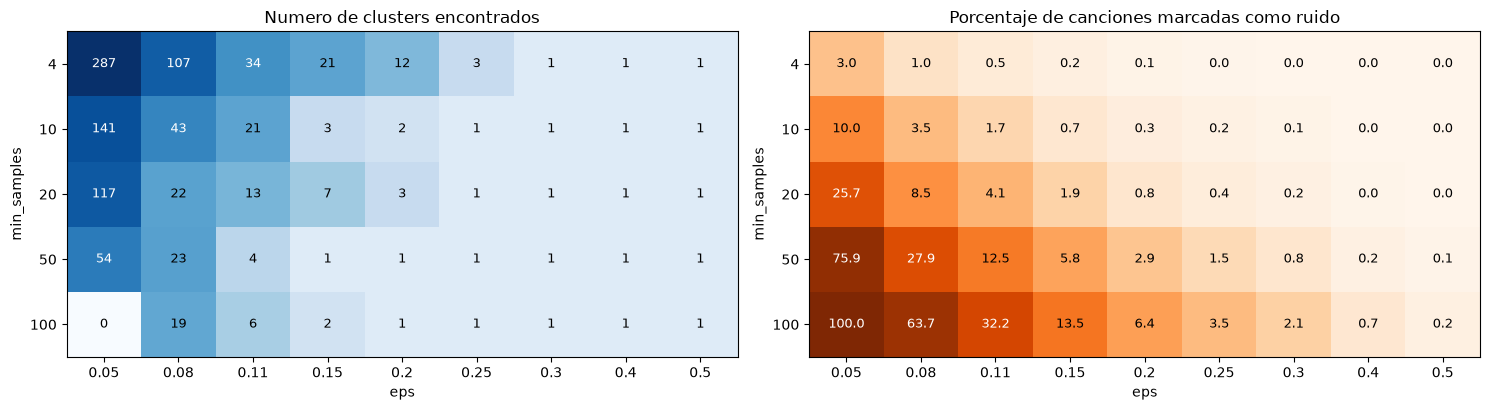

In [35]:
VALORES_EPS = [0.05, 0.08, 0.11, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

inicio = time.time()
filas_barrido = []
for m in VALORES_MIN_SAMPLES:
    for eps in VALORES_EPS:
        etiquetas = DBSCAN(eps=eps, min_samples=m).fit_predict(X_pca)
        filas_barrido.append({'min_samples': m, 'eps': eps, 'Clusters': etiquetas.max() + 1,
                              '% ruido': (etiquetas == -1).mean() * 100})
print(f"Tiempo del barrido ({len(filas_barrido)} modelos): {time.time() - inicio:.1f} s")

df_barrido = pd.DataFrame(filas_barrido)
mapa_clusters = df_barrido.pivot(index='min_samples', columns='eps', values='Clusters')
mapa_ruido = df_barrido.pivot(index='min_samples', columns='eps', values='% ruido')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, mapa, titulo, formato, color_mapa in [
        (axes[0], mapa_clusters, 'Numero de clusters encontrados', '{:.0f}', 'Blues'),
        (axes[1], mapa_ruido, 'Porcentaje de canciones marcadas como ruido', '{:.1f}', 'Oranges')]:
    # Escala logaritmica de color para que los valores grandes no oculten a los pequenos
    ax.imshow(np.log1p(mapa.values), cmap=color_mapa, aspect='auto')
    umbral_texto = np.log1p(mapa.values).max() * 0.6
    for i in range(mapa.shape[0]):
        for j in range(mapa.shape[1]):
            valor = mapa.values[i, j]
            ax.text(j, i, formato.format(valor), ha='center', va='center', fontsize=9,
                    color='white' if np.log1p(valor) > umbral_texto else 'black')
    ax.set_xticks(range(mapa.shape[1]))
    ax.set_xticklabels(mapa.columns)
    ax.set_yticks(range(mapa.shape[0]))
    ax.set_yticklabels(mapa.index)
    ax.set_xlabel('eps')
    ax.set_ylabel('min_samples')
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

**Analisis del barrido:**
- **`eps` pequeno (0.05 - 0.11):** el radio es demasiado chico para la densidad de los datos. DBSCAN fragmenta las canciones en decenas o cientos de clusters, o declara ruido a una gran parte de ellas (con `min_samples = 100` y `eps = 0.05`, el 100% queda como ruido).
- **`eps` grande (>= 0.25):** con cualquier `min_samples` queda **1 solo cluster**, y con `eps` de 0.4 o 0.5 el ruido baja a casi 0%. DBSCAN pierde su capacidad de detectar canciones atipicas porque todo queda conectado.
- **En ninguna combinacion aparecen dos o mas grupos grandes.** Cuando hay mas de un cluster, el segundo mas grande nunca llega al 7% del tamano del mayor: son fragmentos de la periferia, no familias de canciones. Esto confirma que, en el plano del PCA, el espacio acustico es **una sola region densa y continua, sin huecos de densidad** que separen familias de canciones.
- La combinacion elegida (`eps = 0.227`, `min_samples = 100`) esta en la zona de transicion entre estos dos extremos: no fragmenta los datos y todavia separa la periferia como ruido. Los valores vecinos dan el mismo resultado (1 cluster, con 6.4% de ruido en `eps = 0.20` y 3.5% en `eps = 0.25`), asi que la eleccion es estable.

### 25.2 Modelo DBSCAN final

Con los hiperparametros elegidos se entrena el modelo final y se analiza que canciones quedan como ruido.

In [36]:
MIN_SAMPLES_FINAL = 100
EPS_FINAL = eps_codo[MIN_SAMPLES_FINAL]

inicio = time.time()
dbscan = DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES_FINAL).fit(X_pca)
etiquetas_db = dbscan.labels_
print(f"Tiempo: {time.time() - inicio:.1f} s")

es_ruido = etiquetas_db == -1
n_clusters_db = etiquetas_db.max() + 1
print(f"DBSCAN final: eps = {EPS_FINAL}, min_samples = {MIN_SAMPLES_FINAL}")
print(f"Clusters encontrados: {n_clusters_db} | Canciones marcadas como ruido: {es_ruido.sum():,} ({es_ruido.mean()*100:.2f}%)")

# Comparacion del perfil acustico: canciones del cluster denso vs canciones atipicas (ruido)
perfil_db = pd.DataFrame({'Ruido (atipicas)': X_clu[es_ruido].median(),
                          'Cluster denso': X_clu[~es_ruido].median()})
perfil_db.loc['% de Hits'] = [clase_real[es_ruido].mean() * 100, clase_real[~es_ruido].mean() * 100]

# Generos mas sobrerrepresentados en el ruido (cuantas veces mas frecuentes que en todo el dataset)
frec_ruido = genero[es_ruido].value_counts(normalize=True)
frec_total = genero.value_counts(normalize=True)
generos_ruido = pd.DataFrame({'Canciones en el ruido': genero[es_ruido].value_counts(),
                              'Veces mas frecuente que en el dataset': (frec_ruido / frec_total[frec_ruido.index])})
print()
print("Generos mas sobrerrepresentados en el ruido:")
print(generos_ruido[generos_ruido['Canciones en el ruido'] >= 30]
      .sort_values('Veces mas frecuente que en el dataset', ascending=False).head(10).round(2).to_string())
perfil_db.round(3)

Tiempo: 1.7 s
DBSCAN final: eps = 0.227, min_samples = 100
Clusters encontrados: 1 | Canciones marcadas como ruido: 3,413 (4.48%)

Generos mas sobrerrepresentados en el ruido:
             Canciones en el ruido  Veces mas frecuente que en el dataset
sleep                          110                                  14.69
new-age                        171                                  11.05
ambient                        149                                   7.86
iranian                        154                                   6.68
opera                          141                                   5.28
disney                         153                                   5.16
children                       196                                   5.04
black-metal                    179                                   4.96
idm                            151                                   4.68
classical                       45                                   4.54


,Ruido (atipicas),Cluster denso
danceability,0.400,0.589
energy,0.368,0.710
loudness,-12.814,-6.695
speechiness,0.048,0.050
acousticness,0.713,0.152
instrumentalness,0.653,0.000
liveness,0.119,0.138
valence,0.165,0.491
tempo,112.787,123.037
duration_ms,200125.000,212694.000


**Analisis del modelo DBSCAN final:**
- **1 cluster denso con 72,704 canciones (95.5%) y 3,413 canciones marcadas como ruido (4.5%).**
- El ruido no es un error del modelo: son las **canciones acusticamente atipicas**. Frente al cluster denso son mucho mas instrumentales (`instrumentalness` mediana 0.65 vs 0.00), acusticas (0.71 vs 0.15), suaves (-12.8 dB vs -6.7 dB) y tristes (`valence` 0.17 vs 0.49).
- Los generos mas sobrerrepresentados en el ruido lo confirman: **sleep** (14.7 veces mas frecuente que en el dataset), **new-age** (11x), **ambient** (7.9x), **opera**, **classical** y **disney**. Tambien aparecen generos de otros extremos del espacio, como **black-metal** (muy ruidoso, poco bailable y de valencia muy baja) e **idm** (electronica experimental). Es decir, el ruido no es solo "musica suave": son las canciones que estan lejos del sonido comun en cualquier direccion.
- **Solo el 6.7% de las canciones atipicas son Hits, contra 14.9% del cluster denso:** tienen menos de la mitad de probabilidad de ser populares. Es una senal util para la aplicacion web: avisar al usuario cuando su cancion tiene un perfil acustico poco comun.

## 26. Graficas: original, K-Means y DBSCAN

Las tres graficas muestran las mismas 76,117 canciones en el plano de las 2 componentes principales:
- **Original:** coloreadas por su clase real (Hit / Nicho).
- **K-Means:** coloreadas por el cluster asignado, con los centroides marcados.
- **DBSCAN:** coloreadas por el cluster asignado; el ruido aparece en gris.

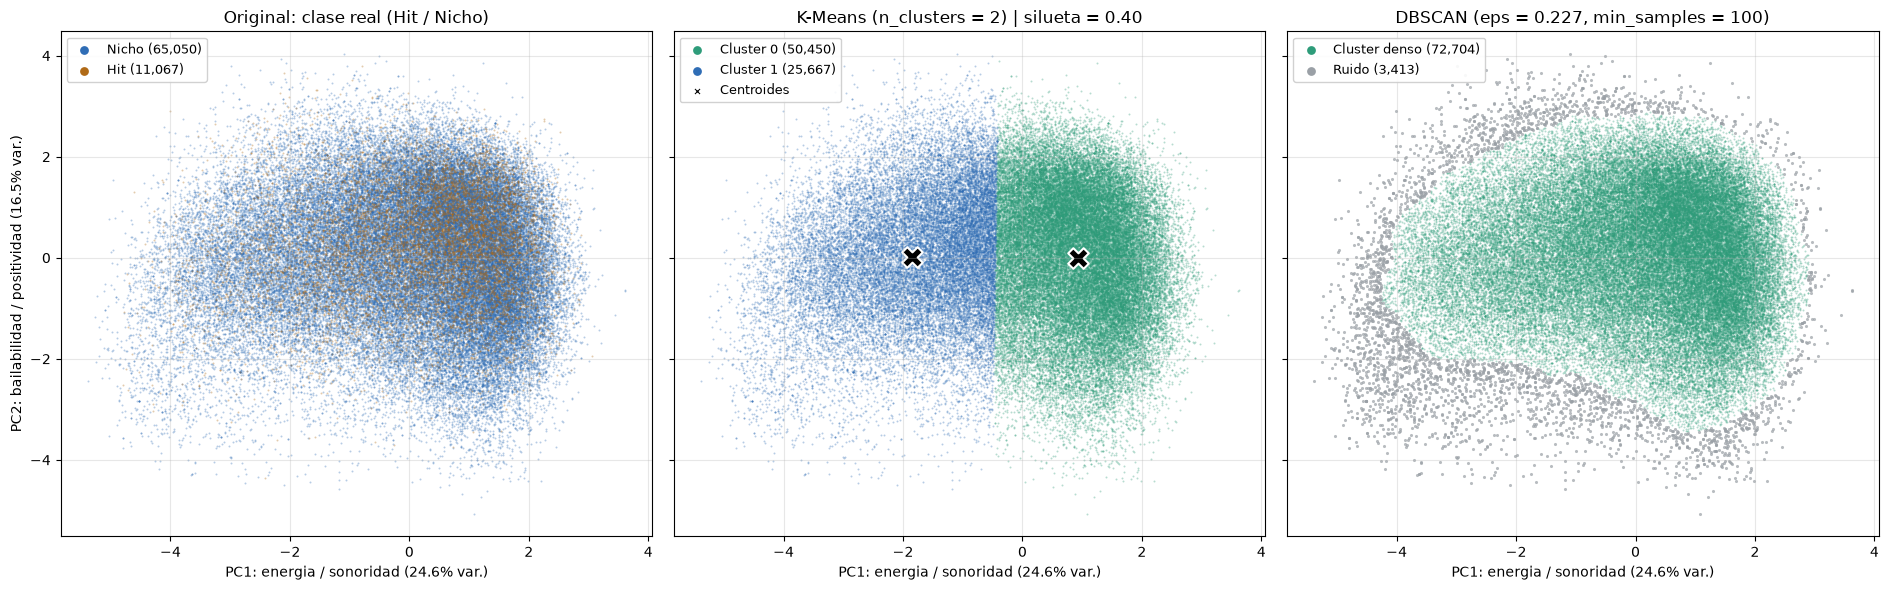

,Grupos,% ruido,Silueta,ARI frente a Hit/Nicho
Original (clase real),2,0.0000,NaN,1.0000
K-Means,2,0.0000,0.4021,-0.0096
DBSCAN,1,4.4839,NaN,-0.0310


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharex=True, sharey=True)
estilo = dict(s=2, alpha=0.35, rasterized=True, linewidths=0)

# 1. Original: clase real (los Hits se dibujan encima para que se vean)
axes[0].scatter(*X_pca[clase_real == 0].T, color=COLOR_AZUL, label=f'Nicho ({(clase_real == 0).sum():,})', **estilo)
axes[0].scatter(*X_pca[clase_real == 1].T, color=COLOR_AMBAR, label=f'Hit ({(clase_real == 1).sum():,})', **estilo)
axes[0].set_title('Original: clase real (Hit / Nicho)')

# 2. K-Means: clusters y centroides
for k, color in zip(range(N_CLASES), [COLOR_VERDE, COLOR_AZUL]):
    axes[1].scatter(*X_pca[etiquetas_km == k].T, color=color,
                    label=f'Cluster {k} ({(etiquetas_km == k).sum():,})', **estilo)
axes[1].scatter(*kmeans.cluster_centers_.T, marker='X', s=220, color='black', edgecolor='white',
                linewidth=1.5, label='Centroides')
axes[1].set_title(f'K-Means (n_clusters = {N_CLASES}) | silueta = {sil_km:.2f}')

# 3. DBSCAN: cluster principal, clusters secundarios (si existen) y ruido
tamanos_db = np.bincount(etiquetas_db[etiquetas_db >= 0])
principal = int(np.argmax(tamanos_db))
axes[2].scatter(*X_pca[etiquetas_db == principal].T, color=COLOR_VERDE,
                label=f'Cluster denso ({(etiquetas_db == principal).sum():,})', **estilo)
secundarios = (etiquetas_db >= 0) & (etiquetas_db != principal)
if secundarios.any():
    axes[2].scatter(*X_pca[secundarios].T, color=COLOR_AMBAR,
                    label=f'Otros clusters ({n_clusters_db - 1}, {secundarios.sum():,} canciones)', s=6, alpha=0.8)
axes[2].scatter(*X_pca[es_ruido].T, color=COLOR_RUIDO, s=5, alpha=0.7, linewidths=0, rasterized=True,
                label=f'Ruido ({es_ruido.sum():,})')
axes[2].set_title(f'DBSCAN (eps = {EPS_FINAL}, min_samples = {MIN_SAMPLES_FINAL})')

for ax in axes:
    ax.set_xlabel(f'PC1: energia / sonoridad ({pca.explained_variance_ratio_[0]*100:.1f}% var.)')
    leyenda = ax.legend(loc='upper left', fontsize=9, framealpha=0.9)
    # Marcadores de la leyenda del mismo tamano y opacos (en el grafico son pequenos y transparentes)
    for marcador in leyenda.legend_handles:
        marcador.set_sizes([40])
        marcador.set_alpha(1)
    ax.grid(alpha=0.3)
axes[0].set_ylabel(f'PC2: bailabilidad / positividad ({pca.explained_variance_ratio_[1]*100:.1f}% var.)')
plt.tight_layout()
plt.show()

# Resumen numerico de los tres agrupamientos
sin_ruido = ~es_ruido
sil_db = (silhouette_score(X_pca[sin_ruido], etiquetas_db[sin_ruido], sample_size=10000, random_state=SEMILLA)
          if n_clusters_db > 1 else np.nan)
pd.DataFrame({
    'Grupos': [N_CLASES, N_CLASES, n_clusters_db],
    '% ruido': [0, 0, es_ruido.mean() * 100],
    'Silueta': [np.nan, sil_km, sil_db],
    'ARI frente a Hit/Nicho': [1.0, ari_km, adjusted_rand_score(clase_real, etiquetas_db)],
}, index=['Original (clase real)', 'K-Means', 'DBSCAN']).round(4)

**Analisis de las tres graficas:**
- **Original:** los Hits (ambar) estan algo mas concentrados en la zona central-derecha (canciones energeticas y bailables), pero siempre mezclados con los Nichos. En el plano acustico no hay ninguna frontera que separe las dos clases. Esto explica visualmente por que ningun modelo de la Entrega 2 supero un F1 de ~0.5.
- **K-Means:** corta la nube en dos con una linea casi vertical sobre PC1, y separa las canciones acusticas y suaves (izquierda) de las energeticas (derecha). K-Means siempre entrega los *k* grupos pedidos, aunque los datos no tengan huecos: es una **particion** de un continuo, no el descubrimiento de grupos naturales. Su frontera no coincide con la de las clases reales (ARI = -0.01).
- **DBSCAN:** no parte la nube. Encuentra el unico nucleo denso y marca como ruido el anillo gris de la periferia (canciones atipicas). Es la evidencia de que los datos **no tienen grupos naturales separados por densidad**. Su ARI frente a Hit / Nicho (-0.03) tambien es practicamente 0.
- Los dos algoritmos responden preguntas distintas: K-Means responde *"de los dos tipos de sonido, a cual se parece mas esta cancion?"*, y DBSCAN responde *"es esta cancion acusticamente normal o atipica?"*.

## Conclusiones de la Entrega 3

| Paso | Decision | Resultado |
|---|---|---|
| Escalado | StandardScaler | Las 10 variables pesan 10% cada una (con MinMaxScaler, de 3% a 21%) |
| PCA | 10 variables acusticas -> 2 componentes | 41.1% de la varianza (con las 126 variables, solo 4.2%) |
| K-Means | `n_clusters = 2` (numero de clases) | Canciones "energeticas" (66%) vs "acusticas / tranquilas" (34%), silueta 0.40 |
| DBSCAN | `eps = 0.227`, `min_samples = 100` | 1 cluster denso (95.5%) + 4.5% de canciones atipicas |

1. **StandardScaler es el escalado adecuado** para algoritmos basados en distancia: da el mismo peso a todas las variables, mientras que con MinMaxScaler el peso depende de la forma de la distribucion de cada variable.
2. **PCA a 2 componentes tiene sentido solo con las variables acusticas.** Los dos ejes son interpretables: energia / sonoridad (PC1) y bailabilidad / positividad (PC2).
3. **K-Means con 2 clusters separa las canciones por energia**, pero esos grupos no tienen relacion con Hit / Nicho (ARI ~0).
4. **Los hiperparametros de DBSCAN se eligieron con un metodo sistematico:** curva de k-distancia (`eps` en el codo) para varios valores de `min_samples`, y un barrido de sensibilidad. Con `min_samples` pequeno se forman cientos de grupos artificiales de pocas canciones; con `eps` grande todo se une en un solo cluster. La combinacion elegida esta en la zona estable entre ambos extremos.
5. **Hallazgo principal: el espacio acustico es un continuo.** DBSCAN no encuentra grupos naturales separados por densidad, solo un nucleo comun y una periferia de canciones atipicas (sleep, new-age, ambient, opera...), que tienen la mitad de probabilidad de ser Hit.
6. **Ni los clusters ni la estructura acustica coinciden con la popularidad.** Esto es consistente con la Entrega 2: el audio por si solo explica una parte limitada del exito de una cancion, porque faltan factores externos como la fama del artista y la promocion.

**Uso en el pipeline de AudioMetrics:**
- El cluster de K-Means se usa como **etiqueta de perfil acustico** de la cancion del usuario ("energetica" o "acustica / tranquila").
- DBSCAN se usa como **detector de canciones atipicas**: si la cancion del usuario queda a mas de `eps` de todos los puntos nucleo, se le avisa que su perfil acustico es poco comun.
- La prediccion de Hit / Nicho sigue a cargo del Random Forest de la Entrega 2.